# Laboratorio de series de tiempo — Flujo vehicular en la estación Illia (2017–2020)

### Plantilla colaborativa para Google Colab · Modelo principal: SARIMA

**Asignatura:** Laboratorio de Series de Tiempo  
**Dataset:** `flujo-vehicular-2017_2021_illia.csv`  
**Equipo:** Marco (líder), Aldana, Brickzon, Vera y Poma  
**Estado:** Plantilla de trabajo; **no contiene entrenamiento ni resultados finales**.

> **Pregunta del laboratorio:** ¿Qué tan bien puede SARIMA pronosticar el número de pasos vehiculares diarios de la estación Illia considerando sus patrones semanales?

> **Decisión metodológica inicial (sujeta a validación empírica):** serie diaria de `cantidad_pasos` agregada por `fecha`; modelo SARIMA con período estacional semanal `s=7`. La selección está motivada por diagnósticos exploratorios previos, pero no presupone exactitud predictiva.

# Organización y reglas compartidas

| Integrante | Bloque a cargo | Subapartados | Alcance |
|---|---|---:|---|
| **Aldana** | Ingesta, calidad y preparación | 5 | CSV completo, inconsistencias, duplicados, serie y particiones |
| **Brickzon** | Exploración y visualización | 5 | Tendencias, ciclo semanal/horario, STL y cambios de nivel |
| **Vera** | Diagnóstico estadístico y diseño de parámetros | 5 | ADF, KPSS, ACF/PACF, diferencias, candidatos y controles |
| **Poma** | Modelado y evaluación | 5 | Baseline, entrenamiento, validación, prueba y residuos |
| **Marco (líder)** | Introducción, conclusiones e integración | 3 | Alcance, interpretación final y control de entrega |

*Reglas de integración del equipo:*

- *Trabajen en este mismo notebook de Colab y coordinen antes de reemplazar celdas ajenas. En el historial de versiones de Colab, anoten cambios relevantes por responsable.*
- *No cambien el archivo fuente; toda transformación se hace en memoria y debe ser reproducible ejecutando las celdas en orden desde un entorno nuevo.*
- *Cada subsección tiene cuatro celdas separadas: título, encargado, indicaciones en cursiva y espacio de desarrollo. No eliminen las tres primeras al implementar.*
- *No inventen métricas ni resultados. Si una prueba no puede ejecutarse, escriban la razón y el impacto en el análisis.*
- *Los ejemplos del profesor son referencias de aprendizaje, no código obligatorio. No añadan LSTM, BiLSTM ni Prophet: el alcance acordado es un único modelo principal SARIMA y un baseline sencillo para contextualizar el error.*
- *La exploración descriptiva puede mostrar toda la historia 2017–2020, pero las decisiones de parámetros, ajustes y selección del modelo deben basarse solo en el entrenamiento y la validación, nunca en el conjunto final de prueba.*
- *No hagan divisiones aleatorias de los datos de series temporales. Definan cortes cronológicos fijos, una única estrategia de pronóstico y un horizonte coherente para comparar métodos.*
- *Antes de considerar terminada una sección, añadan bajo los resultados una interpretación breve en sus propias palabras, indicando qué se observó y qué limitación tiene.*

**Contrato de variables para enlazar secciones**

| Variable | Tipo y significado | La produce |
|---|---|---|
| `df_raw` | `pandas.DataFrame` con los registros originales | Aldana |
| `serie_diaria` | `pandas.Series` numérica, índice diario completo, nombre `cantidad_pasos` | Aldana |
| `train`, `val`, `test` | Series cronológicas sin solapamiento; validación 56 días y prueba 28 días | Aldana |
| `candidatos_sarima` | Lista de parámetros `(order, seasonal_order)` fundamentados | Vera |
| `tabla_validacion` | Comparación de candidatos y baseline en validación | Poma |
| `modelo_final` | SARIMA reentrenado con `train + val` | Poma |
| `pred_test`, `pred_base_test` | Pronósticos con índice igual al de `test` | Poma |
| `tabla_metricas` | Resultados de MAE, RMSE y mejora frente al baseline | Poma |

*Si alguna variable no puede construirse con garantías de calidad, documenten el impedimento y acuerden con Marco el tratamiento antes de avanzar. El bloque de entrenamiento no debe ocultar problemas detectados en preparación.*

# 1. Planteamiento del laboratorio

## 1.1. Problema, objetivo y justificación inicial

**Encargado: Marco (líder)**

*Propósito: Definir en términos académicos qué se pronosticará y por qué se estudiará una serie temporal diaria con SARIMA.*

*Indicaciones de desarrollo:*
1. *Redacta un planteamiento breve del problema: pronóstico del total diario de pasos vehiculares en Illia, no predicción individual de vehículos, tipo de pago ni sentido.*
2. *Incluye un objetivo general y de dos a tres objetivos específicos medibles: construir la serie diaria, describir su comportamiento, diagnosticar estacionalidad semanal y evaluar pronósticos fuera de muestra.*
3. *Explica por qué SARIMA es el candidato inicial: existen patrones semanales, pero su rendimiento se comprobará con validación y prueba; no prometas que es el modelo más preciso.*
4. *Delimita el periodo a 2017–2020; el nombre del CSV menciona 2021, pero el diagnóstico anterior no encontró registros de ese año.*
5. *Explicita que `cantidad_pasos` representa un conteo agregado; evita equiparar sin explicación cada registro del CSV a un vehículo individual.*

*Entregable verificable: Un texto de 2–4 párrafos y objetivos verificables, listo para exposición.*

*Criterios de aceptación: No hay afirmaciones de causalidad ni de precisión no demostradas; el objetivo coincide con lo que realmente se evaluará.*

> **[Marco: redactar aquí la introducción, el objetivo general y los objetivos específicos.]**

**Problema:** [Completar]

**Objetivo general:** [Completar]

**Objetivos específicos:** [Completar]

**Justificación del modelo elegido:** [Completar]

In [ ]:
# MARCO — configuración planificada y evidencia verificada (sin cargar datos).
marco_alcance = {
    "configuracion_planificada": {
        "modelo_principal": "SARIMA",
        "objetivo": "total diario de pasos vehiculares (suma de cantidad_pasos)",
        "frecuencia": "diaria",
        "periodo_estacional_dias": 7,
        "validacion_dias": 56,
        "prueba_dias": 28,
        "cobertura_historica_esperada": "2017–2020",
    },
    "estado_verificacion": "PENDIENTE: la configuración está planificada; la ejecución con el CSV aún debe comprobar cobertura y particiones.",
    "resultados_verificados": None,
}

try:
    from IPython.display import display
    display(marco_alcance)
except ImportError:
    print(marco_alcance)


# 2. Carga, auditoría y preparación de los datos — Aldana

## 2.1. Configuración de Colab y lectura segura del CSV

**Encargado: Aldana**

*Propósito: Preparar un entorno reproducible y cargar el archivo completo sin alterar los registros originales.*

*Indicaciones de desarrollo:*
1. *Confirma que el notebook se ejecuta en Google Colab con Python 3; utiliza las bibliotecas disponibles y anota las versiones relevantes de pandas, numpy y statsmodels. Instala solo lo indispensable.*
2. *Permite dos formas de ubicar el CSV: subirlo al panel Archivos de Colab (`/content`) o montarlo desde Google Drive; documenta en una línea qué ruta deben editar los compañeros.*
3. *Lee las ocho columnas con pandas preservando las cadenas originales; comprueba el delimitador y la lectura UTF-8 sin reinterpretar etiquetas dañadas a ciegas. Si la lectura falla, comunica el problema en la salida.*
4. *Muestra dimensiones, nombres de columnas y `head()`/`dtypes`; evita imprimir los 1.048.575 registros completos en Colab.*
5. *Mantén `df_raw` como referencia inmutable para controles posteriores; usa copias para transformar fechas o categorías.*

*Entregable verificable: Bloque de inicialización funcional y variable `df_raw`, con tamaño del archivo verificado.*

*Criterios de aceptación: Al reiniciar el entorno y corregir solo `RUTA_CSV`, la celda carga datos sin rutas locales de Windows ni secretos.*

In [1]:
# ALDANA — 2.1. Lectura íntegra, reproducible y sin modificar la fuente.
from pathlib import Path
from importlib.util import find_spec
from importlib.metadata import version
import csv
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    EN_COLAB = find_spec('google.colab') is not None
except ModuleNotFoundError:
    EN_COLAB = False
NOMBRE_CSV = 'flujo-vehicular-2017_2021_illia.csv'
# En Colab edita SOLO RUTA_CSV: /content/archivo.csv o /content/drive/MyDrive/.../archivo.csv.
RUTA_CSV = Path('/content') / NOMBRE_CSV if EN_COLAB else Path(NOMBRE_CSV)
# También funciona desde la raíz del repositorio o desde la carpeta del notebook.
if not EN_COLAB and not RUTA_CSV.is_file():
    RUTA_CSV = Path('Semana 12') / 'Lab Series de Tiempo Caso flujo-vehicular-2017_2021_illia' / NOMBRE_CSV
if EN_COLAB and str(RUTA_CSV).startswith('/content/drive/'):
    from google.colab import drive
    drive.mount('/content/drive')

# Parámetros compartidos: no alterar sin documentarlo con todo el equipo.
SEMILLA = 42
PERIODO_SEMANAL = 7
DIAS_VALIDACION = 56
DIAS_PRUEBA = 28

if sys.version_info.major != 3:
    raise RuntimeError('Se requiere Python 3.')
print('Entorno:', 'Google Colab' if EN_COLAB else 'Python local / Jupyter (compatible con Colab)')
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | statsmodels {version("statsmodels")}')
print('CSV:', RUTA_CSV, '| bytes:', RUTA_CSV.stat().st_size if RUTA_CSV.is_file() else 'no localizado')
if not RUTA_CSV.is_file():
    raise FileNotFoundError('Sube el CSV a Archivos de Colab o configura RUTA_CSV en Google Drive.')

def _aldana_sha256_archivo(ruta):
    huella = hashlib.sha256()
    with ruta.open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            huella.update(bloque)
    return huella.hexdigest()

def _aldana_huella(objeto):
    valores = pd.util.hash_pandas_object(objeto, index=True).to_numpy().tobytes()
    esquema = repr((getattr(objeto, 'columns', None), objeto.dtypes)).encode('utf-8')
    return hashlib.sha256(valores + esquema).hexdigest()

COLUMNAS_ESPERADAS = ['periodo', 'fecha', 'hora_inicio', 'estacion', 'sentido',
                      'tipo_vehiculo', 'forma_pago', 'cantidad_pasos']
try:
    # UTF-8 estricto: no sustituir bytes ni reinterpretar etiquetas ya dañadas.
    with RUTA_CSV.open(encoding='utf-8', errors='strict', newline='') as archivo:
        muestra_csv = archivo.read(8192)
    delimitador = csv.Sniffer().sniff(muestra_csv, delimiters=',;\t|').delimiter
    df_raw = pd.read_csv(RUTA_CSV, sep=delimitador, encoding='utf-8',
                         encoding_errors='strict', dtype='string', keep_default_na=False,
                         na_filter=False, on_bad_lines='error', skip_blank_lines=False)
except (UnicodeError, pd.errors.ParserError, csv.Error) as error:
    print('Lectura fallida; revisar el archivo con el equipo:', type(error).__name__, str(error))
    raise
if df_raw.empty or list(df_raw.columns) != COLUMNAS_ESPERADAS:
    raise ValueError(f'Se esperan datos y estas ocho columnas en orden: {COLUMNAS_ESPERADAS}. Recibidas: {list(df_raw.columns)}')
SHA256_CSV = _aldana_sha256_archivo(RUTA_CSV)
HUELLA_DF_RAW = _aldana_huella(df_raw)
print(f'Delimitador: {delimitador!r} | dimensiones: {df_raw.shape} | SHA-256: {SHA256_CSV}')
display(df_raw.head(5))
display(df_raw.dtypes.rename('tipo_recibido').to_frame())
display(Markdown(f'**Interpretación (Aldana):** Se leyeron las ocho columnas y los {len(df_raw):,} '
                 'registros completos como cadenas, incluidos los textos originales y la categoría N/D. '
                 '`df_raw` queda reservado como referencia: las transformaciones se harán en una copia '
                 'y su huella se volverá a comprobar al terminar la preparación. Leer todo el archivo '
                 'disponible no demuestra que la exportación de origen esté completa.'))


Entorno: Python local / Jupyter (compatible con Colab)
Python 3.14.7 | pandas 3.1.0 | numpy 2.5.4 | statsmodels 0.15.0
CSV: Semana 12\Lab Series de Tiempo Caso flujo-vehicular-2017_2021_illia\flujo-vehicular-2017_2021_illia.csv | bytes: 56697333


Delimitador: ',' | dimensiones: (1048575, 8) | SHA-256: ea62be448b7134c5a7c2893e2684cea3a3a586f7df7921f7b9a7085549387dd5


,periodo,fecha,hora_inicio,estacion,sentido,tipo_vehiculo,forma_pago,cantidad_pasos
0,2017,01/01/2017,0,illia,Centro,Liviano,no cobrado,252
1,2017,01/01/2017,0,illia,Centro,Liviano,efectivo,1
2,2017,01/01/2017,0,illia,Centro,Liviano,telepase,100
3,2017,01/01/2017,0,illia,Centro,Pesado,telepase,2
4,2017,01/01/2017,0,illia,Centro,Pesado,telepase,1


,tipo_recibido
periodo,string
fecha,string
hora_inicio,string
estacion,string
sentido,string
tipo_vehiculo,string
forma_pago,string
cantidad_pasos,string


**Interpretación (Aldana):** Se leyeron las ocho columnas y los 1,048,575 registros completos como cadenas, incluidos los textos originales y la categoría N/D. `df_raw` queda reservado como referencia: las transformaciones se harán en una copia y su huella se volverá a comprobar al terminar la preparación. Leer todo el archivo disponible no demuestra que la exportación de origen esté completa.

## 2.2. Validación de esquema, fechas, horas y valores

**Encargado: Aldana**

*Propósito: Identificar de forma cuantitativa problemas en los tipos y campos imprescindibles para agregación temporal.*

*Indicaciones de desarrollo:*
1. *Comprueba la presencia y el orden lógico de las columnas: `periodo`, `fecha`, `hora_inicio`, `estacion`, `sentido`, `tipo_vehiculo`, `forma_pago` y `cantidad_pasos`.*
2. *Analiza nulos por columna, tipos recibidos, fechas no interpretables, horas fuera de 0–23, año de `periodo` incompatible con `fecha` y cantidades nulas, negativas o no numéricas.*
3. *Convierte las fechas en una copia de trabajo: contempla `DD/MM/YYYY` y textos con componente `00:00`; usa `dayfirst=True` y verifica los extremos de calendario y los fallos de parseo.*
4. *Revisa el rango real de los años y verifica explícitamente si hay observaciones de 2021, sin asumirlo por el nombre del archivo.*
5. *Resume todos los hallazgos en una tabla corta con cantidad afectada, ejemplo y tratamiento propuesto; no corrijas ni elimines registros sin justificación.*

*Entregable verificable: Tabla de integridad y una copia de trabajo con fecha normalizada, sin modificar `df_raw`.*

*Criterios de aceptación: La conversión de fecha es verificable, los registros problemáticos quedan identificados y no se crean fechas silenciosamente.*

In [2]:
# ALDANA — 2.2. Validación explícita de campos; conversión solo en copia.
if list(df_raw.columns) != COLUMNAS_ESPERADAS:
    raise ValueError('Cambió el esquema respecto a la carga de 2.1.')
df_trabajo = df_raw.copy(deep=True)
_aldana_vacios = df_raw.isna() | df_raw.apply(lambda c: c.str.strip().eq(''))
tabla_nulos = pd.DataFrame({'tipo_recibido': df_raw.dtypes.astype(str),
                            'nulos_o_vacios': _aldana_vacios.sum()})
display(tabla_nulos)

# Solo se admiten DD/MM/YYYY y DD/MM/YYYY 00:00. No inferir MM/DD/YYYY.
_aldana_texto_fecha = df_raw['fecha'].str.strip()
_aldana_fecha_admitida = _aldana_texto_fecha.str.fullmatch(r'\d{2}/\d{2}/\d{4}(?: 00:00)?', na=False)
_aldana_fecha_limpia = _aldana_texto_fecha.str.replace(r' 00:00$', '', regex=True)
df_trabajo['fecha'] = pd.to_datetime(_aldana_fecha_limpia.where(_aldana_fecha_admitida),
                                     format='%d/%m/%Y', dayfirst=True, errors='coerce').dt.normalize()
_aldana_numeros = {c: pd.to_numeric(df_raw[c], errors='coerce')
                   for c in ('periodo', 'hora_inicio', 'cantidad_pasos')}
_aldana_anio = _aldana_numeros['periodo']
_aldana_hora = _aldana_numeros['hora_inicio']
_aldana_pasos = _aldana_numeros['cantidad_pasos']
_aldana_fallos = {
    'fecha_invalida': df_trabajo['fecha'].isna(),
    'hora_invalida': _aldana_hora.isna() | ~_aldana_hora.between(0, 23) | _aldana_hora.mod(1).ne(0),
    'periodo_invalido_o_incompatible': _aldana_anio.isna() | _aldana_anio.ne(df_trabajo['fecha'].dt.year),
    'cantidad_nula_o_no_numerica': _aldana_pasos.isna(),
    'cantidad_infinita': _aldana_pasos.notna() & ~np.isfinite(_aldana_pasos.astype(float)),
    'cantidad_negativa': _aldana_pasos.lt(0).fillna(False),
    'cantidad_no_entera': _aldana_pasos.notna() & _aldana_pasos.mod(1).ne(0),
}
_aldana_filas_calidad = []
for columna in df_raw.columns:
    mascara = _aldana_vacios[columna]
    _aldana_filas_calidad.append({'control': f'Nulos/vacíos: {columna}', 'filas': int(mascara.sum()),
        'ejemplo': repr(df_raw.loc[mascara, columna].iloc[0]) if mascara.any() else 'Ninguno',
        'tratamiento': 'Conservar; si es campo crítico, detener la agregación y consultar al equipo.'})
for control, mascara in _aldana_fallos.items():
    _aldana_filas_calidad.append({'control': control, 'filas': int(mascara.sum()),
        'ejemplo': repr(df_raw.loc[mascara, ['periodo', 'fecha', 'hora_inicio', 'cantidad_pasos']].head(1).to_dict('records')) if mascara.any() else 'Ninguno',
        'tratamiento': 'No imputar ni eliminar: detener preparación si hay casos.'})
_aldana_filas_calidad.append({'control': 'cantidad_cero', 'filas': int(_aldana_pasos.eq(0).sum()),
    'ejemplo': 'Conteo observado igual a cero', 'tratamiento': 'Conservar si existe; no confundir con ausencia.'})
tabla_calidad = pd.DataFrame(_aldana_filas_calidad)
display(tabla_calidad)
# Los controles pueden solaparse; filas_problematicas cuenta cada registro una sola vez.
_aldana_mascara_problemas = pd.DataFrame(_aldana_fallos).any(axis=1)
filas_problematicas = df_raw.loc[_aldana_mascara_problemas].copy()
if not filas_problematicas.empty:
    raise ValueError(f'{len(filas_problematicas)} registros críticos identificados en filas_problematicas. Consultar a Marco antes de agregar.')
for columna in ('periodo', 'hora_inicio', 'cantidad_pasos'):
    df_trabajo[columna] = _aldana_numeros[columna].astype('int64')
formatos_fecha = pd.Series({
    'DD/MM/YYYY': int(_aldana_texto_fecha.str.fullmatch(r'\d{2}/\d{2}/\d{4}').sum()),
    'DD/MM/YYYY 00:00': int(_aldana_texto_fecha.str.endswith(' 00:00').sum()),
}, name='registros')
cobertura_por_anio = df_trabajo.groupby(df_trabajo['fecha'].dt.year).agg(
    registros=('fecha', 'size'), dias=('fecha', 'nunique'),
    primera_fecha=('fecha', 'min'), ultima_fecha=('fecha', 'max'))
display(formatos_fecha.to_frame())
display(cobertura_por_anio)
_aldana_n_2021 = int(df_trabajo['fecha'].dt.year.eq(2021).sum())
print('Registros de 2021:', _aldana_n_2021, '| estaciones:', sorted(df_trabajo['estacion'].unique()))
display(df_trabajo.dtypes.rename('tipo_trabajo').to_frame())
display(Markdown(f'**Interpretación (Aldana):** Los {len(df_trabajo):,} registros son interpretables '
    f'sin eliminar filas: no se detectaron errores críticos de fecha, hora, año o cantidad; '
    f'hay {_aldana_n_2021} observaciones de 2021. El calendario real va de '
    f'{df_trabajo["fecha"].min():%d/%m/%Y} a {df_trabajo["fecha"].max():%d/%m/%Y}. '
    'Normalizar fechas y tipos numéricos permite agregar, pero no resuelve las repeticiones '
    'ni los cambios de categorías, que se auditan a continuación.'))


,tipo_recibido,nulos_o_vacios
periodo,string,0
fecha,string,0
hora_inicio,string,0
estacion,string,0
sentido,string,0
tipo_vehiculo,string,0
forma_pago,string,0
cantidad_pasos,string,0


,control,filas,ejemplo,tratamiento
0,Nulos/vacíos: periodo,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
1,Nulos/vacíos: fecha,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
2,Nulos/vacíos: hora_inicio,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
3,Nulos/vacíos: estacion,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
4,Nulos/vacíos: sentido,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
5,Nulos/vacíos: tipo_vehiculo,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
6,Nulos/vacíos: forma_pago,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
7,Nulos/vacíos: cantidad_pasos,0,Ninguno,"Conservar; si es campo crítico, detener la agr..."
8,fecha_invalida,0,Ninguno,No imputar ni eliminar: detener preparación si...
9,hora_invalida,0,Ninguno,No imputar ni eliminar: detener preparación si...


,registros
DD/MM/YYYY,964348
DD/MM/YYYY 00:00,84227


,registros,dias,primera_fecha,ultima_fecha
fecha,,,,
2017,291900,365,2017-01-01,2017-12-31
2018,299519,365,2018-01-01,2018-12-31
2019,161133,365,2019-01-01,2019-12-31
2020,296023,366,2020-01-01,2020-12-31


Registros de 2021: 0 | estaciones: ['illia']


,tipo_trabajo
periodo,int64
fecha,datetime64[us]
hora_inicio,int64
estacion,string
sentido,string
tipo_vehiculo,string
forma_pago,string
cantidad_pasos,int64


**Interpretación (Aldana):** Los 1,048,575 registros son interpretables sin eliminar filas: no se detectaron errores críticos de fecha, hora, año o cantidad; hay 0 observaciones de 2021. El calendario real va de 01/01/2017 a 31/12/2020. Normalizar fechas y tipos numéricos permite agregar, pero no resuelve las repeticiones ni los cambios de categorías, que se auditan a continuación.

## 2.3. Duplicados, categorías y posible truncamiento

**Encargado: Aldana**

*Propósito: Documentar anomalías de captura que podrían sesgar los totales de tránsito.*

*Indicaciones de desarrollo:*
1. *Cuantifica filas duplicadas exactas y duplicados por clave lógica (`fecha`, `hora_inicio`, `estacion`, `sentido`, `tipo_vehiculo`, `forma_pago`); distingue la repetición literal de una clave con cantidades distintas.*
2. *Calcula cuántos pasos aportan las repeticiones exactas y presenta solo como simulación la diferencia de total si se descartaran, manteniendo intactos los datos base.*
3. *Tabula las categorías de `tipo_vehiculo` y `forma_pago` por año; registra etiquetas con el carácter `�` y cambios de taxonomía que impiden hacer comparaciones categóricas directas.*
4. *Señala que el archivo contiene aparentemente 1.048.575 filas, cifra coincidente con el límite de filas de Excel menos cabecera: es una alerta de posible truncamiento, no una prueba.*
5. *Cierra con la decisión de tratamiento para el análisis principal: conservar registros salvo evidencia sólida que permita depurar; documenta qué incertidumbre permanece.*

*Entregable verificable: Una tabla de duplicados, otra de categorías por año y un párrafo de riesgos.*

*Criterios de aceptación: Nunca se ejecuta `drop_duplicates` sobre la serie principal sin justificación y la auditoría no confunde duplicados con vehículos.*

In [3]:
# ALDANA — 2.3. Auditoría de repeticiones y taxonomías, sin depurar la fuente.
CLAVE_LOGICA = ['fecha', 'hora_inicio', 'estacion', 'sentido', 'tipo_vehiculo', 'forma_pago']
_aldana_exactas_excedentes = df_raw.duplicated(keep='first')
_aldana_exactas_miembros = df_raw.duplicated(keep=False)
# Se informa también la clave literal; para la clave lógica se normalizaron fecha/hora en 2.2.
resumen_claves = df_trabajo.groupby(CLAVE_LOGICA, dropna=False).agg(
    registros=('cantidad_pasos', 'size'), cantidades_distintas=('cantidad_pasos', 'nunique'))
_aldana_claves_repetidas = resumen_claves['registros'].gt(1)
_aldana_claves_conflictivas = resumen_claves['cantidades_distintas'].gt(1)
resumen_duplicados = pd.DataFrame([
    {'control': 'Repeticiones exactas excedentes (ocho cadenas, keep=first)', 'cantidad': int(_aldana_exactas_excedentes.sum()), 'unidad': 'filas'},
    {'control': 'Todos los miembros de grupos de filas exactas repetidas', 'cantidad': int(_aldana_exactas_miembros.sum()), 'unidad': 'filas'},
    {'control': 'Repeticiones excedentes por clave literal', 'cantidad': int(df_raw.duplicated(CLAVE_LOGICA).sum()), 'unidad': 'filas'},
    {'control': 'Repeticiones excedentes por clave normalizada', 'cantidad': int(df_trabajo.duplicated(CLAVE_LOGICA).sum()), 'unidad': 'filas'},
    {'control': 'Claves normalizadas con más de un registro', 'cantidad': int(_aldana_claves_repetidas.sum()), 'unidad': 'claves'},
    {'control': 'Claves repetidas con cantidades distintas', 'cantidad': int(_aldana_claves_conflictivas.sum()), 'unidad': 'claves'},
    {'control': 'Claves repetidas con una sola cantidad distinta', 'cantidad': int((_aldana_claves_repetidas & ~_aldana_claves_conflictivas).sum()), 'unidad': 'claves'},
])
display(resumen_duplicados)
display(resumen_claves.loc[_aldana_claves_conflictivas].head(5))
_aldana_total_original = int(df_trabajo['cantidad_pasos'].sum())
_aldana_pasos_repetidos = int(df_trabajo.loc[_aldana_exactas_excedentes, 'cantidad_pasos'].sum())
sensibilidad_duplicados = pd.DataFrame([{
    'escenario': 'SIMULACIÓN: excluir solo repeticiones exactas excedentes',
    'total_principal': _aldana_total_original,
    'pasos_excedentes': _aldana_pasos_repetidos,
    'total_simulado': _aldana_total_original - _aldana_pasos_repetidos,
    'diferencia_pct': -100 * _aldana_pasos_repetidos / _aldana_total_original if _aldana_total_original else np.nan,
}])
display(sensibilidad_duplicados)

_aldana_tablas_categorias = []
_aldana_cambios = []
for campo in ('tipo_vehiculo', 'forma_pago'):
    tabla = pd.crosstab(df_trabajo[campo], df_trabajo['fecha'].dt.year).sort_index()
    tabla.index.name = 'categoria'
    tabla.insert(0, 'campo', campo)
    _aldana_tablas_categorias.append(tabla.reset_index().set_index(['campo', 'categoria']))
    previo = None
    for anio, grupo in df_trabajo.groupby(df_trabajo['fecha'].dt.year):
        actuales = set(grupo[campo].unique())
        if previo is not None:
            _aldana_cambios.append({'campo': campo, 'anio': anio,
                'aparecen_vs_anio_previo': ', '.join(sorted(actuales - previo)) or 'Ninguna',
                'dejan_de_observarse': ', '.join(sorted(previo - actuales)) or 'Ninguna'})
        previo = actuales
categorias_por_anio = pd.concat(_aldana_tablas_categorias)
cambios_taxonomia = pd.DataFrame(_aldana_cambios)
etiquetas_danadas = categorias_por_anio.loc[
    categorias_por_anio.index.get_level_values('categoria').str.contains('�', regex=False)]
print('Registros por categoría original y año (0 = categoría no observada ese año):')
display(categorias_por_anio)
display(cambios_taxonomia)
print('Etiquetas que ya contienen el carácter de reemplazo Unicode:')
display(etiquetas_danadas)
alerta_truncamiento = len(df_raw) == 2**20 - 1
print('Coincidencia con límite de Excel menos cabecera:', alerta_truncamiento)
display(Markdown(f'**Interpretación (Aldana):** Hay {int(_aldana_exactas_excedentes.sum()):,} '
    f'repeticiones exactas excedentes que aportan {_aldana_pasos_repetidos:,} pasos. Excluirlas '
    f'daría {_aldana_total_original - _aldana_pasos_repetidos:,} pasos solo en una simulación; '
    '**el análisis principal conserva todas las filas**. Una clave repetida con cantidades distintas '
    'no demuestra duplicación errónea y una fila no equivale a un vehículo. Las etiquetas dañadas '
    'y los cambios de taxonomía impiden comparaciones categóricas directas sin un diccionario externo; '
    'no se reinterpretan. La coincidencia del número de filas con el límite de Excel es una alerta '
    'de posible truncamiento, no una prueba: falta contrastar la exportación con la fuente original.'))


,control,cantidad,unidad
0,"Repeticiones exactas excedentes (ocho cadenas,...",48616,filas
1,Todos los miembros de grupos de filas exactas ...,91182,filas
2,Repeticiones excedentes por clave literal,361849,filas
3,Repeticiones excedentes por clave normalizada,361849,filas
4,Claves normalizadas con más de un registro,197104,claves
5,Claves repetidas con cantidades distintas,189605,claves
6,Claves repetidas con una sola cantidad distinta,7499,claves


registros  \
fecha      hora_inicio estacion sentido   tipo_vehiculo forma_pago              
2017-01-01 0           illia    Centro    Pesado        telepase            2   
           1           illia    Centro    Liviano       efectivo            2   
                                Provincia Liviano       efectivo            2   
                                          Pesado        telepase            2   
           2           illia    Centro    Liviano       efectivo            2   

                                                                    cantidades_distintas  
fecha      hora_inicio estacion sentido   tipo_vehiculo forma_pago                        
2017-01-01 0           illia    Centro    Pesado        telepase                       2  
           1           illia    Centro    Liviano       efectivo                       2  
                                Provincia Liviano       efectivo                       2  
                                          Pesado        telepase                       2  
           2           illia    Centro    Liviano       efectivo                       2

,escenario,total_principal,pasos_excedentes,total_simulado,diferencia_pct
0,SIMULACIÓN: excluir solo repeticiones exactas ...,120175861,96737,120079124,-0.080496


Registros por categoría original y año (0 = categoría no observada ese año):


fecha                                                        2017    2018  \
campo         categoria                                                     
tipo_vehiculo Auto                                              0       0   
              Auto con trailer                                  0       0   
              Liviano                                      130734  135900   
              Moto                                              0       0   
              N/D                                               0       0   
              Pago Doble Auto                                   0       0   
              Pago Doble Auto con trailer / Pesado 2 Ejes       0       0   
              Pago doble Moto                                   0       0   
              Pesado                                       161166  163619   
              Pesados 2 Ejes                                    0       0   
              Pesados 3 Ejes                                    0       0   
              Pesados 4 Ejes                                    0       0   
              Pesados 5 Ejes                                    0       0   
              Pesados 6 Ejes                                    0       0   
forma_pago    cpp                                               0       0   
              efectivo                                     104230   99996   
              exento                                        39201   37498   
              infraccion                                    24526   29459   
              mercado pago                                      0       0   
              monedero                                         14       0   
              no cobrado                                    21881   23454   
              rec.deuda                                         0       0   
              tag                                               0       0   
              tarjeta discapacidad                          22145   19191   
              tarjeta magnética                                 0       0   
              telepase                                      79903   89921   
              violación                                         0       0   

fecha                                                        2019    2020  
campo         categoria                                                    
tipo_vehiculo Auto                                              0  133478  
              Auto con trailer                                  0    4686  
              Liviano                                      100861       0  
              Moto                                              0   35385  
              N/D                                               0   30012  
              Pago Doble Auto                                   0    4116  
              Pago Doble Auto con trailer / Pesado 2 Ejes       0      74  
              Pago doble Moto                                   0     780  
              Pesado                                        60272       0  
              Pesados 2 Ejes                                    0   56975  
              Pesados 3 Ejes                                    0   10808  
              Pesados 4 Ejes                                    0    4275  
              Pesados 5 Ejes                                    0    9792  
              Pesados 6 Ejes                                    0    5642  
forma_pago    cpp                                               0    2913  
              efectivo                                      34643   52373  
              exento                                        29204   23745  
              infraccion                                    24015       0  
              mercado pago                                      0    2318  
              monedero                                          0       0  
              no cobrado                                    21344       0  
              rec.

,campo,anio,aparecen_vs_anio_previo,dejan_de_observarse
0,tipo_vehiculo,2018,Ninguna,Ninguna
1,tipo_vehiculo,2019,Ninguna,Ninguna
2,tipo_vehiculo,2020,"Auto, Auto con trailer, Moto, N/D, Pago Doble ...","Liviano, Pesado"
3,forma_pago,2018,Ninguna,monedero
4,forma_pago,2019,Ninguna,Ninguna
5,forma_pago,2020,"cpp, mercado pago, rec.deuda, tag, tarjeta mag...","infraccion, no cobrado, tarjeta discapacidad, ..."


Etiquetas que ya contienen el carácter de reemplazo Unicode:


,fecha,2017,2018,2019,2020
campo,categoria,,,,


Coincidencia con límite de Excel menos cabecera: True


**Interpretación (Aldana):** Hay 48,616 repeticiones exactas excedentes que aportan 96,737 pasos. Excluirlas daría 120,079,124 pasos solo en una simulación; **el análisis principal conserva todas las filas**. Una clave repetida con cantidades distintas no demuestra duplicación errónea y una fila no equivale a un vehículo. Las etiquetas dañadas y los cambios de taxonomía impiden comparaciones categóricas directas sin un diccionario externo; no se reinterpretan. La coincidencia del número de filas con el límite de Excel es una alerta de posible truncamiento, no una prueba: falta contrastar la exportación con la fuente original.

## 2.4. Construcción y verificación de la serie diaria

**Encargado: Aldana**

*Propósito: Crear la serie de modelado con una observación diaria y un conteo agregado de pasos.*

*Indicaciones de desarrollo:*
1. *Agrupa por la fecha normalizada y suma `cantidad_pasos` de todos los sentidos, horas, tipos de vehículo y formas de pago para producir un único valor por día.*
2. *Ordena el índice cronológicamente; construye el calendario esperado y distingue fechas sin registro de días que realmente tuvieron cero pasos. No rellenes ausencias con cero por defecto.*
3. *Comprueba el número de fechas, los extremos, la suma global frente a `df_raw`, valores negativos y duplicación accidental del índice.*
4. *Asegura que el resultado sea un `pd.Series` llamado `serie_diaria`, numérico, con índice `DatetimeIndex` y frecuencia diaria cuando sea válido.*
5. *Incluye una tabla pequeña con los primeros y últimos días y una figura inicial, explicando que la agregación cambia la unidad de análisis de filas categóricas a conteos por día.*

*Entregable verificable: `serie_diaria` lista para ser utilizada por Brickzon, Vera y Poma, con pruebas de integridad.*

*Criterios de aceptación: La suma de la serie coincide con el total de la fuente, salvo diferencias explícitamente documentadas, y no hay fechas duplicadas en el índice.*

,control,cumple
0,Una Series numérica llamada cantidad_pasos,True
1,"Índice DatetimeIndex diario, único y ordenado",True
2,Calendario exacto entre extremos de la fuente,True
3,Sin días ausentes ni valores nulos,True
4,Conteos finitos y no negativos,True
5,Total diario igual al total original,True
6,Se conservaron todos los registros,True


Fechas sin registros: [] | días con cero observado: []
Total fuente: 120175861 | total serie: 120175861


,cantidad_pasos
fecha,
2017-01-01,45478
2017-01-02,89289
2017-01-03,92602
2017-01-04,95813
2017-01-05,100044
2020-12-27,39616
2020-12-28,71737
2020-12-29,79831
2020-12-30,77414


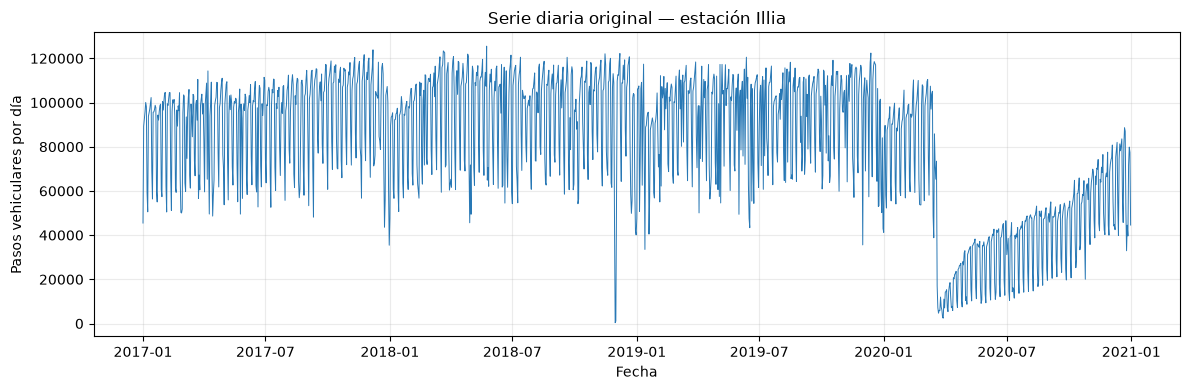

**Interpretación (Aldana):** La agregación produce 1,461 días y 120,175,861 pasos, exactamente el total de la fuente. La unidad pasa de registros categóricos/horarios a pasos totales por día, sumando todos los sentidos y categorías. No se eliminaron repeticiones ni se imputaron ausencias. Tener todos los días del calendario no garantiza que cada día contenga las 24 horas: esa cobertura se comprueba en 2.5.

In [4]:
# ALDANA — 2.4. Suma diaria conservando registros, incluidos los sospechosos.
_aldana_agrupada = df_trabajo.groupby('fecha')['cantidad_pasos'].sum(min_count=1).sort_index()
calendario_esperado = pd.date_range(_aldana_agrupada.index.min(), _aldana_agrupada.index.max(),
                                     freq='D', name='fecha')
fechas_sin_registro = calendario_esperado.difference(_aldana_agrupada.index)
# reindex deja NaN si un día no tiene registros: nunca convertirlo automáticamente a cero.
serie_diaria = _aldana_agrupada.reindex(calendario_esperado).rename('cantidad_pasos')
dias_cero_observados = _aldana_agrupada.index[_aldana_agrupada.eq(0)]
_aldana_suma_fuente = int(pd.to_numeric(df_raw['cantidad_pasos'], errors='raise').sum())
_aldana_controles_serie = {
    'Una Series numérica llamada cantidad_pasos': isinstance(serie_diaria, pd.Series) and pd.api.types.is_numeric_dtype(serie_diaria.dtype) and serie_diaria.name == 'cantidad_pasos',
    'Índice DatetimeIndex diario, único y ordenado': isinstance(serie_diaria.index, pd.DatetimeIndex) and serie_diaria.index.is_unique and serie_diaria.index.is_monotonic_increasing and serie_diaria.index.freqstr == 'D',
    'Calendario exacto entre extremos de la fuente': serie_diaria.index.equals(calendario_esperado),
    'Sin días ausentes ni valores nulos': len(fechas_sin_registro) == 0 and not serie_diaria.isna().any(),
    'Conteos finitos y no negativos': bool(np.isfinite(serie_diaria.to_numpy(dtype=float)).all() and serie_diaria.ge(0).all()),
    'Total diario igual al total original': serie_diaria.sum() == _aldana_suma_fuente,
    'Se conservaron todos los registros': len(df_trabajo) == len(df_raw),
}
tabla_integridad_serie = pd.DataFrame([{'control': c, 'cumple': bool(v)} for c, v in _aldana_controles_serie.items()])
display(tabla_integridad_serie)
print('Fechas sin registros:', list(fechas_sin_registro), '| días con cero observado:', list(dias_cero_observados))
print('Total fuente:', _aldana_suma_fuente, '| total serie:', serie_diaria.sum())
if not all(_aldana_controles_serie.values()):
    raise ValueError('La serie no cumple el contrato. Revisar tabla_integridad_serie con Marco; no imputar ni entrenar.')
tabla_extremos_serie = pd.concat([serie_diaria.head(5), serie_diaria.tail(5)]).to_frame()
display(tabla_extremos_serie)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie_diaria.index, serie_diaria.to_numpy(), linewidth=0.7, color='#2878B5')
ax.set(title='Serie diaria original — estación Illia', xlabel='Fecha', ylabel='Pasos vehiculares por día')
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
display(Markdown(f'**Interpretación (Aldana):** La agregación produce {len(serie_diaria):,} '
    f'días y {_aldana_suma_fuente:,} pasos, exactamente el total de la fuente. La unidad pasa '
    'de registros categóricos/horarios a pasos totales por día, sumando todos los sentidos y categorías. '
    'No se eliminaron repeticiones ni se imputaron ausencias. Tener todos los días del calendario '
    'no garantiza que cada día contenga las 24 horas: esa cobertura se comprueba en 2.5.'))


## 2.5. Incidentes de 2018 y partición cronológica sellada

**Encargado: Aldana**

*Propósito: Registrar los conteos sospechosos y entregar los conjuntos fijos para validación y prueba.*

*Indicaciones de desarrollo:*
1. *Inspecciona los totales de los días 29/11/2018, 30/11/2018 y 01/12/2018; registra además las horas ausentes identificadas en el diagnóstico. No confundas bajo tránsito con una falla de registro demostrada.*
2. *Mantén la serie íntegra como análisis principal; si se realiza sensibilidad frente a anomalías, crea una variante claramente etiquetada y separada, nunca una sustitución silenciosa.*
3. *Separa cronológicamente los últimos 28 días de `serie_diaria` como `test` y los 56 días inmediatamente anteriores como `val`; el resto debe ser `train`.*
4. *Verifica las fechas iniciales/finales, número de puntos, ausencia de solapamientos y continuidad entre tres conjuntos. Muestra un gráfico de la separación y los conteos por segmento.*
5. *Declara expresamente que `test` queda reservado y no se usará para elegir orden, transformar datos con estadísticas futuras ni ajustar hiperparámetros.*

*Entregable verificable: Tres variables compartidas (`train`, `val`, `test`) y un registro de las anomalías de 2018.*

*Criterios de aceptación: 56 días de validación y 28 de prueba; series sin superposición y con índices diarios ordenados.*

Horas sin registros (no son ceros observados):


,fecha,hora_inicio
0,2018-11-29,22
1,2018-11-29,23
2,2018-11-30,0
3,2018-11-30,1
4,2018-11-30,2
5,2018-11-30,3
6,2018-11-30,4
7,2018-11-30,5
8,2018-11-30,6
9,2018-12-01,3


,pasos_observados,registros,horas_observadas,horas_ausentes
fecha,,,,
2018-11-29,47938,653,22,"[22, 23]"
2018-11-30,387,17,17,"[0, 1, 2, 3, 4, 5, 6]"
2018-12-01,1121,58,23,[3]
2018-12-30,42043,495,23,[7]


,cantidad_pasos
fecha,
2018-11-28,108912
2018-11-29,47938
2018-11-30,387
2018-12-01,1121
2018-12-02,57785


**Interpretación de incidentes (Aldana):** El 29/11, 30/11 y 01/12/2018 presentan totales observados de 47,938, 387, 1,121 pasos, respectivamente. También se detecta una hora sin registros el 30/12/2018. La ausencia de registros horarios es verificable, pero no demuestra por sí sola una falla de captura ni explica todos los conteos bajos. Se conserva la serie íntegra como análisis principal; no se corrigen estos días ni se interpolan valores. Brickzon debe explicitar el denominador de horas observadas, y Vera/Poma considerar esta limitación.

,control,cumple
0,Validación de 56 días y prueba de 28,True
1,"Series diarias, no vacías, finitas y sin índic...",True
2,Sin fechas compartidas,True
3,Fronteras contiguas,True
4,Reconstrucción exacta de índices y valores,True
5,df_raw permanece intacto,True
6,Archivo fuente permanece intacto,True


,conjunto,inicio,fin,dias,huella_sha256
0,train,2017-01-01,2020-10-08,1377,082949c5751b476ea3db3b57da037b0b07a069e185acb9...
1,val,2020-10-09,2020-12-03,56,10c52057b488f72bffd6d20d732d59e6aa4cd984b6aa25...
2,test,2020-12-04,2020-12-31,28,3f729db3b064b8b550b3381932b715734caa96b9423ab2...


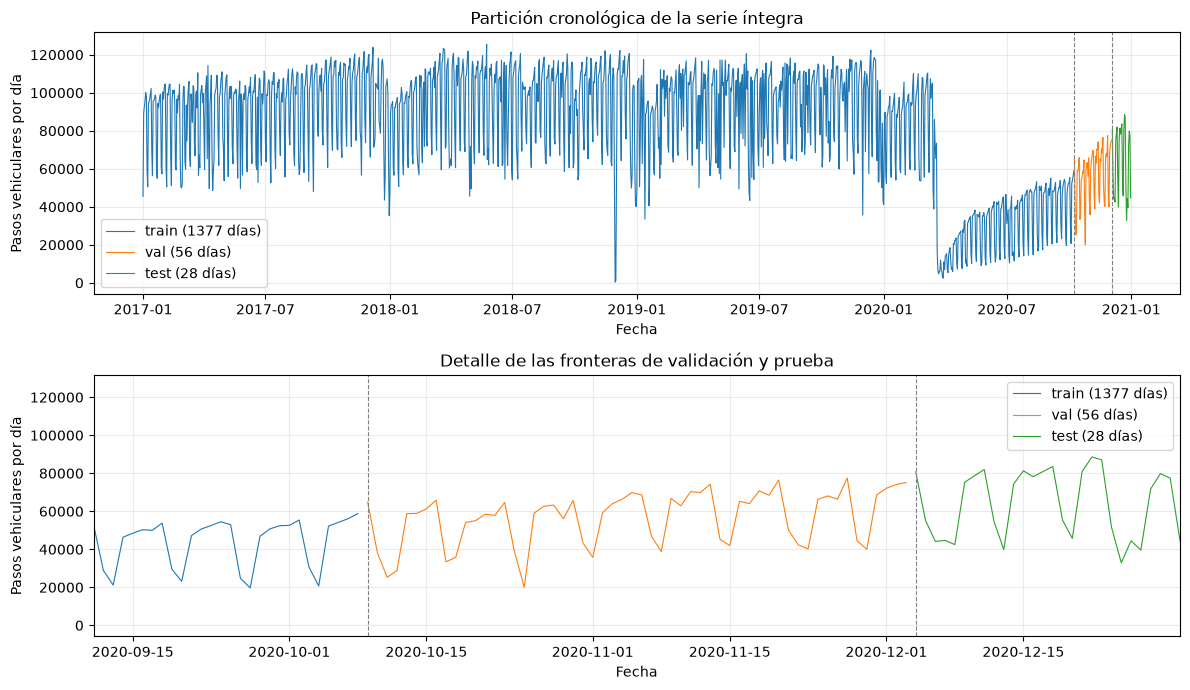

**Interpretación y protocolo (Aldana):** Se entregan 1,377 días de entrenamiento (01/01/2017–08/10/2020), 56 de validación (09/10/2020–03/12/2020) y 28 de prueba (04/12/2020–31/12/2020), sin solapamientos ni discontinuidad. **Test queda reservado para la evaluación final:** no se usará para elegir órdenes, transformaciones ni hiperparámetros. Vera diagnosticará con train; Poma comparará pronósticos directos de 56 días en val y, tras congelar parámetros, reentrenará con train+val para pronosticar 28 días sin actualización con observaciones de test. Las figuras de separación son descriptivas. Las huellas permiten detectar cambios accidentales; no eliminan la incertidumbre sobre duplicados, horas sin registro y posible truncamiento.

In [5]:
# ALDANA — 2.5. Cobertura horaria, incidentes y cortes cronológicos fijos.
_aldana_horas_observadas = pd.MultiIndex.from_frame(df_trabajo[['fecha', 'hora_inicio']]).unique()
_aldana_horas_esperadas = pd.MultiIndex.from_product([calendario_esperado, range(24)],
                                                      names=['fecha', 'hora_inicio'])
tabla_huecos_horarios = _aldana_horas_esperadas.difference(_aldana_horas_observadas).to_frame(index=False)
_aldana_huecos_por_fecha = tabla_huecos_horarios.groupby('fecha')['hora_inicio'].agg(list)
print('Horas sin registros (no son ceros observados):')
display(tabla_huecos_horarios)
_aldana_fechas_incidentes = pd.DatetimeIndex(['2018-11-29', '2018-11-30', '2018-12-01'])
# Incluir además cualquier otro día con huecos, aunque no estuviera en el diagnóstico previo.
_aldana_fechas_incidentes = _aldana_fechas_incidentes.union(_aldana_huecos_por_fecha.index).sort_values()
tabla_incidentes_2018 = pd.DataFrame(index=_aldana_fechas_incidentes.rename('fecha'))
tabla_incidentes_2018['pasos_observados'] = serie_diaria.reindex(_aldana_fechas_incidentes)
tabla_incidentes_2018['registros'] = df_trabajo.groupby('fecha').size().reindex(_aldana_fechas_incidentes)
tabla_incidentes_2018['horas_observadas'] = df_trabajo.groupby('fecha')['hora_inicio'].nunique().reindex(_aldana_fechas_incidentes)
tabla_incidentes_2018['horas_ausentes'] = [list(_aldana_huecos_por_fecha.get(fecha, [])) for fecha in _aldana_fechas_incidentes]
display(tabla_incidentes_2018)
display(serie_diaria.loc['2018-11-28':'2018-12-02'].to_frame())
display(Markdown('**Interpretación de incidentes (Aldana):** El 29/11, 30/11 y 01/12/2018 '
    'presentan totales observados de ' + ', '.join(f'{serie_diaria.loc[f]:,}' for f in pd.DatetimeIndex(['2018-11-29', '2018-11-30', '2018-12-01'])) +
    ' pasos, respectivamente. También se detecta una hora sin registros el 30/12/2018. '
    'La ausencia de registros horarios es verificable, pero no demuestra por sí sola una falla '
    'de captura ni explica todos los conteos bajos. Se conserva la serie íntegra como análisis '
    'principal; no se corrigen estos días ni se interpolan valores. Brickzon debe explicitar '
    'el denominador de horas observadas, y Vera/Poma considerar esta limitación.'))

if len(serie_diaria) < DIAS_VALIDACION + DIAS_PRUEBA + 2 * PERIODO_SEMANAL:
    raise ValueError('No hay suficiente historia para los tres segmentos acordados.')
if serie_diaria.isna().any():
    raise ValueError('Hay días ausentes: consultar al equipo antes de sellar las particiones.')
train = serie_diaria.iloc[:-(DIAS_VALIDACION + DIAS_PRUEBA)].copy()
val = serie_diaria.iloc[-(DIAS_VALIDACION + DIAS_PRUEBA):-DIAS_PRUEBA].copy()
test = serie_diaria.iloc[-DIAS_PRUEBA:].copy()
_aldana_partes = {'train': train, 'val': val, 'test': test}
_aldana_controles_particion = {
    'Validación de 56 días y prueba de 28': len(val) == 56 and len(test) == 28,
    'Series diarias, no vacías, finitas y sin índices repetidos': all(
        not s.empty and s.index.is_unique and s.index.is_monotonic_increasing
        and s.index.equals(pd.date_range(s.index[0], periods=len(s), freq='D'))
        and np.isfinite(s.to_numpy(dtype=float)).all() for s in _aldana_partes.values()),
    'Sin fechas compartidas': all(a.index.intersection(b.index).empty for a, b in ((train, val), (train, test), (val, test))),
    'Fronteras contiguas': train.index[-1] + pd.Timedelta(days=1) == val.index[0] and val.index[-1] + pd.Timedelta(days=1) == test.index[0],
    'Reconstrucción exacta de índices y valores': pd.concat([train, val, test]).equals(serie_diaria),
    'df_raw permanece intacto': _aldana_huella(df_raw) == HUELLA_DF_RAW,
    'Archivo fuente permanece intacto': _aldana_sha256_archivo(RUTA_CSV) == SHA256_CSV,
}
tabla_integridad_particiones = pd.DataFrame([{'control': c, 'cumple': bool(v)} for c, v in _aldana_controles_particion.items()])
display(tabla_integridad_particiones)
if not all(_aldana_controles_particion.values()):
    raise ValueError('No se sellan las particiones: revisar los controles fallidos.')
resumen_particiones = pd.DataFrame([{'conjunto': nombre, 'inicio': s.index[0], 'fin': s.index[-1],
    'dias': len(s), 'huella_sha256': _aldana_huella(s)} for nombre, s in _aldana_partes.items()])
display(resumen_particiones)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for nombre, s in _aldana_partes.items():
    for ax in axes:
        ax.plot(s.index, s.to_numpy(), linewidth=0.8, label=f'{nombre} ({len(s)} días)')
for ax in axes:
    ax.axvline(val.index[0], color='gray', linestyle='--', linewidth=0.8)
    ax.axvline(test.index[0], color='gray', linestyle='--', linewidth=0.8)
    ax.set(xlabel='Fecha', ylabel='Pasos vehiculares por día')
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_title('Partición cronológica de la serie íntegra')
axes[1].set_title('Detalle de las fronteras de validación y prueba')
axes[1].set_xlim(val.index[0] - pd.Timedelta(days=28), test.index[-1])
fig.tight_layout()
plt.show()
registro_preparacion_aldana = {
    'sha256_csv': SHA256_CSV, 'huella_df_raw': HUELLA_DF_RAW,
    'registros': len(df_raw), 'dias': len(serie_diaria), 'pasos': int(serie_diaria.sum()),
    'horas_sin_registros': len(tabla_huecos_horarios),
    'tratamiento': 'Serie íntegra: sin deduplicación, imputación, escalado ni recorte de anomalías.',
    'test_reservado': True, 'particiones': resumen_particiones.to_dict('records'),
}
display(Markdown(f'**Interpretación y protocolo (Aldana):** Se entregan {len(train):,} días '
    f'de entrenamiento ({train.index[0]:%d/%m/%Y}–{train.index[-1]:%d/%m/%Y}), '
    f'{len(val)} de validación ({val.index[0]:%d/%m/%Y}–{val.index[-1]:%d/%m/%Y}) y '
    f'{len(test)} de prueba ({test.index[0]:%d/%m/%Y}–{test.index[-1]:%d/%m/%Y}), sin '
    'solapamientos ni discontinuidad. **Test queda reservado para la evaluación final:** '
    'no se usará para elegir órdenes, transformaciones ni hiperparámetros. Vera diagnosticará '
    'con train; Poma comparará pronósticos directos de 56 días en val y, tras congelar parámetros, '
    'reentrenará con train+val para pronosticar 28 días sin actualización con observaciones de test. '
    'Las figuras de separación son descriptivas. Las huellas permiten detectar cambios accidentales; '
    'no eliminan la incertidumbre sobre duplicados, horas sin registro y posible truncamiento.'))


# 3. Exploración y descripción temporal — Brickzon

## 3.1. Estadísticas y evolución del flujo vehicular

**Encargado: Brickzon**

*Propósito: Describir la magnitud y dinámica del tránsito a lo largo del periodo observado.*

*Indicaciones de desarrollo:*
1. *Presenta una tabla de media, mediana, desviación estándar, mínimo, máximo y percentiles de la serie diaria; indica las fechas de los extremos.*
2. *Grafica el flujo diario completo con ejes y unidades legibles; añade una media móvil de 7 o 28 días para visualizar cambios de nivel sin reemplazar los datos originales.*
3. *Calcula totales por año y promedios diarios por año y mes, con una tabla compacta que permita comparar años con distinto número de días.*
4. *Comenta con números el contraste entre 2017–2019 y 2020, sin afirmar que un evento externo sea causalmente responsable.*
5. *Deja claras las diferencias entre un conteo diario, un total mensual y un promedio de días; evita etiquetar todo como cantidad de vehículos individuales.*

*Entregable verificable: Una tabla descriptiva y una o dos gráficas claras, con interpretación.*

*Criterios de aceptación: Las fechas de ejes son correctas, las unidades están definidas y todas las cifras proceden de la serie creada por Aldana.*

In [ ]:
# TODO — BRICKZON: estadísticas y curva temporal.
# Entradas: serie_diaria, train, val, test.
# Salidas: resumen_descriptivo, figuras de serie y tendencia.
# Los gráficos históricos pueden mostrar todo el rango; no usar test para ajustar modelos.

## 3.2. Patrón de día de la semana y fines de semana

**Encargado: Brickzon**

*Propósito: Medir y comunicar la estacionalidad semanal relevante para SARIMA.*

*Indicaciones de desarrollo:*
1. *Agrupa los días por lunes–domingo y calcula promedio, mediana y dispersión; ordena las etiquetas de forma natural para evitar gráficos alfabéticos.*
2. *Compara días laborables frente a fines de semana y reporta diferencias absolutas y porcentuales, indicando sobre qué conjunto se calcularon.*
3. *Construye un gráfico de barras de promedios por día y, si aporta valor, una representación que compare los perfiles de 2017, 2018, 2019 y 2020.*
4. *Analiza si se mantiene la forma semanal pese a los cambios de nivel; diferencia similitud de perfiles de estabilidad en los volúmenes.*
5. *Relaciona lo observado con la hipótesis de período estacional `s=7`, pero deja la confirmación estadística a las pruebas de Vera.*

*Entregable verificable: Tabla lunes–domingo, una figura semanal y un comentario numérico de estabilidad.*

*Criterios de aceptación: No se confunden correlaciones de perfiles con precisión predictiva y la elección de período se argumenta con observaciones.*

In [ ]:
# TODO — BRICKZON: ciclo semanal.
# Entradas: serie_diaria / train.
# Salidas: tabla_dia_semana, figura semanal y comparación anual.
# Preparar la explicación de la estacionalidad s=7.

## 3.3. Patrones intradiarios como contexto, no como objetivo

**Encargado: Brickzon**

*Propósito: Aprovechar la información de `hora_inicio` para explicar por qué se observa variación de tránsito, sin cambiar la granularidad de modelado.*

*Indicaciones de desarrollo:*
1. *A partir de `df_trabajo`, suma los pasos por hora 0–23 para obtener el perfil horario medio; usa una tasa por hora observada cuando compares promedios.*
2. *Identifica horas punta y valle y contrasta, si es pertinente, días laborables frente a fines de semana.*
3. *Revisa la existencia de huecos horarios documentados por Aldana; no imputes horas faltantes con cero para obtener promedios.*
4. *Produce a lo sumo una figura de línea por hora y una tabla compacta de máximos y mínimos; no construyas un segundo pipeline predictivo horario.*
5. *Explica por qué esta exploración es descriptiva y por qué el objetivo operativo y la evaluación se mantienen diarios.*

*Entregable verificable: Una visualización horaria acompañada de su interpretación y sus limitaciones.*

*Criterios de aceptación: No se entrena un modelo horario ni se confunden sumas acumuladas con promedios por intervalo.*

In [ ]:
# TODO — BRICKZON: perfil horario contextual.
# Entradas: df_trabajo (fecha normalizada, hora_inicio y cantidad_pasos).
# Salidas: figura del perfil 0–23 y tabla de horas altas/bajas.
# No cambiar la variable objetivo: seguirá siendo diaria.

## 3.4. Descomposición STL de la estacionalidad semanal

**Encargado: Brickzon**

*Propósito: Separar descriptivamente tendencia, componente semanal y residuos observados.*

*Indicaciones de desarrollo:*
1. *Aplica STL con período 7 a la serie de entrenamiento para no orientar decisiones metodológicas con el conjunto de prueba; informa si usas la opción robusta.*
2. *Presenta los componentes observada, tendencia, estacional y residual, manteniendo el calendario y escalas legibles.*
3. *Comenta la amplitud del patrón semanal, sus variaciones a través del tiempo y el papel de anomalías que afecten componentes.*
4. *Si reportas razones de varianzas de componentes, explica que no necesariamente suman 100 % porque pueden existir covarianzas.*
5. *Relaciona el resultado con el análisis por día de la semana y documenta si STL no resulta interpretable por cambios de régimen.*

*Entregable verificable: Gráfico de descomposición semanal y explicación de máximo dos párrafos.*

*Criterios de aceptación: El período STL es 7 y el diagnóstico de selección se hace con `train`, nunca con `test`.*

In [ ]:
# TODO — BRICKZON: STL robusto semanal con entrenamiento.
# Entradas: train.
# Salidas sugeridas: resultado_stl, figura de cuatro componentes.
# Usar statsmodels.tsa.seasonal.STL con period=7.

## 3.5. Cambios de nivel en 2020 y síntesis visual

**Encargado: Brickzon**

*Propósito: Contextualizar las rupturas de serie que podrían dificultar los pronósticos.*

*Indicaciones de desarrollo:*
1. *Compara nivel y dispersión mensual entre años, prestando atención a marzo y abril de 2020; presenta cifras, no solo impresiones visuales.*
2. *Señala el mínimo extraordinario de noviembre–diciembre de 2018 que Aldana encontró y explica cómo podría influir en líneas y promedios.*
3. *Usa una línea o gráfico mensual con anotaciones discretas para mostrar 2020; no declares automáticamente causas externas de cambios observados.*
4. *Escribe una conclusión de exploración con tres hallazgos cuantitativos que justifiquen estudiar un ciclo semanal y vigilar los cambios de régimen.*
5. *Entrega a Vera y Poma una nota de riesgos concretos (ruptura 2020 y registros incompletos 2018), sin proponer tratamientos no consensuados.*

*Entregable verificable: Una figura final y un resumen de hallazgos/limitaciones reutilizable en las conclusiones.*

*Criterios de aceptación: Todos los cambios se cuantifican y no se confunden hipótesis sobre causas con hechos.*

In [ ]:
# TODO — BRICKZON: análisis de 2020 y síntesis de figuras.
# Entradas: serie_diaria, train y tablas de Aldana.
# Salidas: comparación mensual/anual y hallazgos cuantitativos.

# 4. Pruebas estadísticas y plan de parametrización — Vera

## 4.1. Contrastes de estacionariedad ADF y KPSS

**Encargado: Vera**

*Propósito: Analizar formalmente la estabilidad estadística de la serie diaria de entrenamiento.*

*Indicaciones de desarrollo:*
1. *Ejecuta ADF sobre `train` en niveles y reporta estadístico, p-valor, rezagos y especificación de constante/tendencia; explica su hipótesis nula de raíz unitaria.*
2. *Ejecuta KPSS sobre la misma serie, reportando especificación y rezagos; recuerda que su hipótesis nula es estacionariedad, a diferencia de ADF.*
3. *Presenta los resultados de forma tabular y explica concordancias o contradicciones entre las pruebas con un nivel de significancia declarado (por ejemplo, 5 %).*
4. *Aclara que un cambio estructural en 2020 y la estacionalidad pueden influir en los contrastes, por lo que un p-valor no constituye una selección automática de SARIMA.*
5. *Si una prueba genera advertencias de límites de tabla o problemas numéricos, regístralos sin reemplazar valores reales por números inventados.*

*Entregable verificable: Tabla ADF/KPSS para entrenamiento en nivel y explicación de hipótesis.*

*Criterios de aceptación: Se especifica conjunto, parámetros de la prueba y conclusión condicionada, sin tocar `val` ni `test`.*

In [ ]:
# TODO — VERA: ADF/KPSS sobre train sin transformaciones futuras.
# Entradas: train.
# Salidas: tabla_estacionariedad_nivel.
# Bibliotecas: statsmodels.tsa.stattools.adfuller, kpss.

## 4.2. Autocorrelación y autocorrelación parcial

**Encargado: Vera**

*Propósito: Examinar las dependencias temporales y los rezagos consistentes con un ciclo semanal.*

*Indicaciones de desarrollo:*
1. *Calcula y grafica ACF y PACF en el conjunto de entrenamiento, especificando el número de rezagos y el método utilizado.*
2. *Reporta ACF de los rezagos 1, 7, 14 y 21 días; si la serie es no estacionaria, aclara el efecto de tendencias y cambios de régimen sobre estos valores.*
3. *Repite el análisis para transformaciones diagnósticas justificadas (por ejemplo primera diferencia o diferencia de 7 días) y distingue claramente cada figura.*
4. *Busca persistencia estacional en múltiplos de 7 sin asegurar que un pico determine inequívocamente los órdenes P, D y Q.*
5. *Explica en pocas líneas qué señales son útiles para acotar candidatos SARIMA y cuáles son ambiguas.*

*Entregable verificable: Figuras ACF/PACF y tabla breve de rezagos interpretados.*

*Criterios de aceptación: Los parámetros diagnósticos se obtienen solo de `train` y no se interpretan niveles no estacionarios como una prueba definitiva.*

In [ ]:
# TODO — VERA: ACF y PACF con train y transformaciones justificadas.
# Entradas: train.
# Salidas: figuras ACF/PACF y tabla_rezagos.
# Bibliotecas: statsmodels.graphics.tsaplots.plot_acf, plot_pacf.

## 4.3. Diferenciación regular y estacional

**Encargado: Vera**

*Propósito: Comprobar qué transformaciones estabilizan la serie antes de proponer parámetros `d` y `D`.*

*Indicaciones de desarrollo:*
1. *Construye sin alterar `train` una primera diferencia y una diferencia semanal de 7 días, registrando cuántas observaciones iniciales se pierden.*
2. *Repite ADF y KPSS cuando sean aplicables para series transformadas y presenta la comparación con la serie original.*
3. *Comprueba si la diferenciación excesiva introduce autocorrelación negativa fuerte o patrones residuales artificiales; no interpretes simplemente un p-valor pequeño como garantía de buen pronóstico.*
4. *Considera qué implica usar a la vez diferencia regular y estacional en términos de longitud e información preservada.*
5. *Recomienda únicamente rangos acotados de `d` y `D` para los candidatos, sin escoger hiperparámetros basados en la prueba final.*

*Entregable verificable: Tabla diagnóstica nivel / diferencia regular / diferencia semanal y sugerencias fundamentadas para `d` y `D`.*

*Criterios de aceptación: Se conoce cuántas filas pierde cada transformación; no se mezclan transformaciones calculadas con datos futuros.*

In [ ]:
# TODO — VERA: transformaciones diagnósticas sobre train.
# Entradas: train.
# Salidas: tabla_diferenciaciones y rangos de d, D.
# No sustituir ni reescalar train globalmente sin registrar decisiones.

## 4.4. Lista acotada de configuraciones SARIMA

**Encargado: Vera**

*Propósito: Entregar a Poma un espacio de búsqueda pequeño, explicable y viable en Colab.*

*Indicaciones de desarrollo:*
1. *Fija el período estacional `s=7` y prepara una lista de entre cuatro y ocho tuplas `(order, seasonal_order)` con órdenes enteros pequeños.*
2. *Justifica los rangos p/q y P/Q de acuerdo con ACF/PACF, diagnósticos de diferenciación y límites computacionales; no conviertas patrones gráficos en certezas.*
3. *Incluye al menos una configuración parsimoniosa como referencia, y evita búsquedas masivas o combinaciones que tarden demasiado sin añadir evidencia.*
4. *No ajustes SARIMA en esta sección: el entrenamiento y comparación de candidatos corresponden a Poma.*
5. *Registra por qué descartaste combinaciones demasiado complejas y acuerda una regla fija de selección por MAE de validación antes de ver `test`.*

*Entregable verificable: Variable `candidatos_sarima` y justificación escrita de cada familia de órdenes.*

*Criterios de aceptación: Toda tupla tiene período 7, la lista está acotada y no contiene decisiones basadas en test.*

In [ ]:
# TODO — VERA: entregar candidatos fundamentados a Poma.
# Formato obligatorio: [(order, seasonal_order), ...]
# Ejemplo de estructura (NO propuesta validada):
# candidatos_sarima = [((p, d, q), (P, D, Q, 7)), ...]
# No completar hasta revisar las pruebas sobre train.

## 4.5. Protocolo de validación y controles contra fuga temporal

**Encargado: Vera**

*Propósito: Establecer reglas verificables para comparar candidatos y proteger el conjunto de prueba.*

*Indicaciones de desarrollo:*
1. *Comprueba junto con Aldana los tres segmentos: `train` histórico, `val` de 56 días y `test` de 28 días, con fechas ordenadas y sin intersecciones.*
2. *Deja escrito que cada candidato se ajustará únicamente a `train` y generará un pronóstico directo de 56 días para `val`, sin utilizar observaciones de validación como datos ya conocidos dentro del horizonte.*
3. *Define que el ganador será el SARIMA válido con menor MAE de validación; el RMSE puede servir como desempate y la convergencia del optimizador debe registrarse.*
4. *Indica que, tras elegir el modelo, se reentrenará sobre `train + val` y se producirá una única predicción directa de los 28 días de `test`, con el mismo procedimiento para el baseline.*
5. *Propón controles contra fuga: no ajustar escaladores con la serie completa, no cambiar parámetros después de ver test, no reemplazar faltantes con estadísticas futuras y mantener índices alineados.*

*Entregable verificable: Protocolo escrito de validación y una celda de aserciones o verificaciones de fechas.*

*Criterios de aceptación: Poma puede implementarlo sin interpretar decisiones ambiguas; la prueba permanece independiente.*

In [ ]:
# TODO — VERA: validaciones de integridad temporal.
# Entradas: train, val, test, candidatos_sarima.
# Salidas: chequeos programáticos y protocolo documentado.
# Comprobar orden, continuidad, len(val)==56, len(test)==28 y ausencia de solape.

# 5. Entrenamiento, pronóstico y evaluación — Poma

## 5.1. Pronóstico base ingenuo estacional

**Encargado: Poma**

*Propósito: Construir una referencia simple para interpretar si SARIMA añade valor real.*

*Indicaciones de desarrollo:*
1. *Implementa un pronóstico semanal ingenuo que repite los últimos siete valores observados del segmento de entrenamiento para cubrir el horizonte futuro completo.*
2. *Para `val`, usa únicamente los últimos siete días de `train` y repítelos hasta completar 56 días; no uses datos reales de `val` dentro del mismo pronóstico directo.*
3. *Calcula MAE y RMSE del baseline en validación y alinea el índice pronosticado con `val`.*
4. *Después de la selección del modelo, vuelve a construir el baseline de prueba a partir de los siete últimos días de `train + val`, cubriendo los 28 días de test.*
5. *Documenta por qué existe este baseline: no es otro modelo principal ni requiere aprendizaje de parámetros, sino un mínimo de referencia para el valor del SARIMA.*

*Entregable verificable: Pronósticos base de validación y prueba, junto con métricas reproducibles.*

*Criterios de aceptación: No hay uso anticipado de observaciones reales del horizonte y ambas predicciones usan el mismo calendario que los valores verdaderos.*

In [ ]:
# POMA — 5.1. Baseline ingenuo estacional semanal; 56 días de validación.
# Entrada: particiones OFICIALES de Aldana. Sin transformación del CSV.
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import mean_absolute_error, mean_squared_error

for nombre in ('train', 'val', 'test'):
    if nombre not in globals():
        raise RuntimeError(f'Falta {nombre}: Aldana debe terminar 2.4–2.5. No se crean particiones artificiales.')

def _poma_verificar_segmento(s, nombre):
    if not isinstance(s, pd.Series) or not isinstance(s.index, pd.DatetimeIndex):
        raise TypeError(f'{nombre} debe ser pd.Series con DatetimeIndex.')
    if s.empty or s.index.has_duplicates or not s.index.is_monotonic_increasing:
        raise ValueError(f'{nombre}: fechas vacías, duplicadas o desordenadas.')
    if not pd.api.types.is_numeric_dtype(s) or s.isna().any():
        raise ValueError(f'{nombre}: valores nulos o no numéricos; consultar a Aldana.')
    if (s < 0).any() or not np.isfinite(s.to_numpy(dtype=float)).all():
        raise ValueError(f'{nombre}: conteos negativos o infinitos.')
    esperado = pd.date_range(s.index[0], periods=len(s), freq='D')
    if not esperado.equals(s.index):
        raise ValueError(f'{nombre}: días no consecutivos; no rellenar ausencias silenciosamente.')

for nombre in ('train', 'val', 'test'):
    _poma_verificar_segmento(globals()[nombre], nombre)
if len(train) < 14 or len(val) != 56 or len(test) != 28:
    raise ValueError('Se requiere train >= 14 días, val = 56 y test = 28.')
if train.index[-1] + pd.Timedelta(days=1) != val.index[0]:
    raise ValueError('train y val deben ser cronológicamente contiguos.')
if val.index[-1] + pd.Timedelta(days=1) != test.index[0]:
    raise ValueError('val y test deben ser cronológicamente contiguos.')

def _poma_baseline_semanal(historia, indice_destino):
    # Pronóstico DIRECTO: ningún dato del horizonte es incorporado mientras se pronostica.
    if len(historia) < 7:
        raise ValueError('Se requieren al menos siete observaciones históricas.')
    patron = historia.iloc[-7:].to_numpy(dtype=float)
    yhat = np.tile(patron, int(np.ceil(len(indice_destino) / 7)))[:len(indice_destino)]
    return pd.Series(yhat, index=indice_destino, name='baseline_s7')

def _poma_mae_rmse(real, pronostico):
    if not real.index.equals(pronostico.index):
        raise ValueError('Índices reales y pronosticados distintos.')
    if not np.isfinite(pronostico.to_numpy(dtype=float)).all():
        raise ValueError('Predicciones no finitas.')
    return (float(mean_absolute_error(real, pronostico)),
            float(np.sqrt(mean_squared_error(real, pronostico))))

pred_base_val = _poma_baseline_semanal(train, val.index)
mae_base_val, rmse_base_val = _poma_mae_rmse(val, pred_base_val)
metricas_base_val = {'MAE': mae_base_val, 'RMSE': rmse_base_val}
display(pd.DataFrame([{'Modelo':'Baseline s=7','MAE':mae_base_val,'RMSE':rmse_base_val}]))
display(Markdown(
    f'**Interpretación:** El baseline de repetición semanal obtuvo MAE={mae_base_val:,.2f} '
    f'y RMSE={rmse_base_val:,.2f} pasos diarios en 56 días de validación. '
    'Es solo una referencia de comparación; no presupone que la estacionalidad sea estable. '
    'El baseline de prueba se creará después de la selección en 5.3.'
))


## 5.2. Entrenamiento de candidatos SARIMA y validación

**Encargado: Poma**

*Propósito: Comparar las configuraciones predefinidas por Vera en un periodo de validación cronológico.*

*Indicaciones de desarrollo:*
1. *Usa `statsmodels` y ajusta cada configuración de `candidatos_sarima` exclusivamente sobre `train`, indicando explícitamente `(p,d,q)` y `(P,D,Q,7)`.*
2. *Para cada ajuste, genera un pronóstico directo de 56 pasos diarios hasta el final de `val`; alinea índices antes de medir errores.*
3. *Registra MAE, RMSE, tiempo de ejecución aproximado, advertencias relevantes y convergencia; captura errores por candidato sin ocultarlos.*
4. *Selecciona por menor MAE de validación entre ajustes válidos, usando la regla de desempate acordada; compara el resultado del ganador con el baseline de 5.1.*
5. *Si ningún candidato converge, informa a Vera y Marco antes de modificar el espacio de búsqueda; no explores `test` para encontrar un modelo más favorable.*

*Entregable verificable: `tabla_validacion` con todos los candidatos y los parámetros del mejor ajuste seleccionado por validación.*

*Criterios de aceptación: Cada fila puede reproducirse, el horizonte es el mismo y no se consulta el conjunto de prueba durante la selección.*

In [ ]:
# POMA — 5.2. SARIMA: entrenar SOLO con train; pronóstico directo 56 días.
# Entrada: candidatos_sarima justificados por Vera (4.4). Test permanece sellado.
import time
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

if 'candidatos_sarima' not in globals():
    raise RuntimeError('Falta candidatos_sarima: Vera debe completar 4.4.')
if not isinstance(candidatos_sarima, (list, tuple)) or not 4 <= len(candidatos_sarima) <= 8:
    raise ValueError('Vera debe entregar de 4 a 8 configuraciones SARIMA.')
if len(set(map(str, candidatos_sarima))) != len(candidatos_sarima):
    raise ValueError('Hay configuraciones repetidas.')

filas = []
for i, candidato in enumerate(candidatos_sarima, 1):
    t0 = time.perf_counter()
    avisos = []
    fila = {'Modelo':f'SARIMA_{i}', 'order':None, 'seasonal_order':None,
            'MAE':np.nan, 'RMSE':np.nan, 'segundos':np.nan,
            'convergencia':False, 'advertencias':'', 'estado':'ERROR'}
    try:
        if not isinstance(candidato, (tuple, list)) or len(candidato) != 2:
            raise ValueError('Formato inválido: ((p,d,q),(P,D,Q,7)).')
        order, seasonal_order = tuple(candidato[0]), tuple(candidato[1])
        if len(order) != 3 or len(seasonal_order) != 4:
            raise ValueError('Longitud incorrecta de órdenes.')
        if not all(isinstance(x, (int, np.integer)) and x >= 0 for x in order + seasonal_order[:3]):
            raise ValueError('Todos los órdenes deben ser enteros no negativos.')
        if seasonal_order[3] != 7:
            raise ValueError('La estacionalidad acordada es de siete días.')
        fila['order'], fila['seasonal_order'] = order, seasonal_order
        with warnings.catch_warnings(record=True) as capturadas:
            warnings.simplefilter('always')
            ajuste = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                             enforce_stationarity=False,
                             enforce_invertibility=False).fit(disp=False, maxiter=200)
            valores = np.asarray(ajuste.get_forecast(steps=len(val)).predicted_mean, dtype=float)
            avisos = [f'{w.category.__name__}: {w.message}' for w in capturadas]
        fila['convergencia'] = bool(ajuste.mle_retvals.get('converged', False))
        if len(valores) != len(val) or not np.isfinite(valores).all():
            raise ValueError('Pronóstico inválido.')
        candidato_val = pd.Series(valores, index=val.index)
        fila['MAE'], fila['RMSE'] = _poma_mae_rmse(val, candidato_val)
        fila['estado'] = 'VÁLIDO' if fila['convergencia'] else 'NO CONVERGIÓ'
    except Exception as error:
        fila['estado'] = 'ERROR'
        avisos.append(f'{type(error).__name__}: {error}')
    finally:
        fila['segundos'] = round(time.perf_counter()-t0, 2)
        fila['advertencias'] = ' | '.join(avisos)[:900] or 'Ninguna'
        filas.append(fila)

base = {'Modelo':'Baseline s=7','order':None,'seasonal_order':None,
        'MAE':mae_base_val,'RMSE':rmse_base_val,'segundos':0.0,
        'convergencia':None,'advertencias':'No aplica','estado':'REFERENCIA'}
tabla_validacion = pd.DataFrame([base] + filas)
display(tabla_validacion)
validos = [x for x in filas if x['estado']=='VÁLIDO' and np.isfinite(x['MAE']) and np.isfinite(x['RMSE'])]
if not validos:
    raise RuntimeError('Ningún SARIMA convergió. Informar a Vera y Marco antes de ajustar órdenes; no mirar test.')
ganador = min(validos, key=lambda x: (x['MAE'], x['RMSE'], x['Modelo']))
parametros_ganadores = ganador['order'], ganador['seasonal_order']
balance_val = 'menor' if ganador['MAE'] < mae_base_val else 'mayor o igual'
display(Markdown(
    f'**Interpretación:** Seleccionado {ganador["Modelo"]} con órdenes {parametros_ganadores} '
    f'por menor MAE de validación ({ganador["MAE"]:,.2f}; RMSE={ganador["RMSE"]:,.2f}). '
    f'Su MAE fue {balance_val} que el baseline ({mae_base_val:,.2f}). '
    'Solo participan candidatos convergentes; los resultados de test no intervienen.'
))


## 5.3. Reentrenamiento final y pronóstico de 28 días

**Encargado: Poma**

*Propósito: Obtener el pronóstico fuera de muestra con la configuración ya elegida.*

*Indicaciones de desarrollo:*
1. *Congela la tupla ganadora y concatena `train + val` de forma cronológica; verifica que no haya índices repetidos.*
2. *Ajusta nuevamente SARIMA sobre toda esa historia disponible y genera un pronóstico directo de 28 días correspondientes exactamente a `test`.*
3. *Guarda el resultado como `pred_test` con índice de fecha igual al de `test`; conserva `modelo_final` y parámetros usados.*
4. *Obtén intervalos de confianza si el método los ofrece y reporta su nivel (por ejemplo 95 %); explica que sus supuestos pueden ser vulnerables a la ruptura de 2020.*
5. *No actualices el modelo usando días reales de `test` dentro del horizonte. Si el pronóstico produce valores negativos, registra el problema y justifica cualquier regla de posprocesamiento establecida antes de evaluar.*

*Entregable verificable: `modelo_final` y `pred_test` con sus 28 fechas, más intervalos si están disponibles.*

*Criterios de aceptación: El conjunto `test` se usa solo como verdad para evaluar, nunca como entrada anticipada al pronóstico.*

In [ ]:
# POMA — 5.3. Ajustar SARIMA ganador a train+val y pronosticar 28 días DIRECTOS.
if 'parametros_ganadores' not in globals():
    raise RuntimeError('Ejecutar 5.2: aún no hay parámetros seleccionados por validación.')
historia_final = pd.concat([train, val])
_poma_verificar_segmento(historia_final, 'historia_final')
if historia_final.index[-1] + pd.Timedelta(days=1) != test.index[0]:
    raise ValueError('La historia y la prueba no son contiguas.')

inicio_final = time.perf_counter()
with warnings.catch_warnings(record=True) as ws_final:
    warnings.simplefilter('always')
    modelo_final = SARIMAX(historia_final, order=parametros_ganadores[0],
                           seasonal_order=parametros_ganadores[1],
                           enforce_stationarity=False,
                           enforce_invertibility=False).fit(disp=False, maxiter=200)
    objeto_pronostico = modelo_final.get_forecast(steps=len(test))
advertencias_finales = [f'{w.category.__name__}: {w.message}' for w in ws_final]
segundos_finales = round(time.perf_counter() - inicio_final, 2)
if not bool(modelo_final.mle_retvals.get('converged', False)):
    raise RuntimeError('El ajuste final no convergió: consultar a Vera y Marco sin mirar resultados de test.')

pronostico_array = np.asarray(objeto_pronostico.predicted_mean, dtype=float)
if len(pronostico_array) != 28 or not np.isfinite(pronostico_array).all():
    raise ValueError('Pronóstico final inválido.')
pred_test = pd.Series(pronostico_array, index=test.index, name='SARIMA')
# El baseline de test utiliza los últimos 7 días de train+val, no de test.
pred_base_test = _poma_baseline_semanal(historia_final, test.index)
conf_int = np.asarray(objeto_pronostico.conf_int(alpha=0.05), dtype=float)
intervalos_test = None
if conf_int.shape == (28, 2) and np.isfinite(conf_int).all():
    intervalos_test = pd.DataFrame(conf_int, index=test.index,
                                   columns=['inferior_95','superior_95'])
print('Orden seleccionado:', parametros_ganadores, '| tiempo (s):', segundos_finales)
print('Advertencias:', ' | '.join(advertencias_finales) or 'Ninguna')
print('Índice de predicción:', pred_test.index.min(), '→', pred_test.index.max())
if (pred_test < 0).any():
    print('ADVERTENCIA: algunos valores pronosticados son negativos; no se recortan silenciosamente.')
display(pd.DataFrame({'SARIMA':pred_test, 'Baseline':pred_base_test}).head())
display(Markdown('**Interpretación:** Se ha producido un solo pronóstico directo de 28 días sin usar '
                 'observaciones reales de test para ajustar ni actualizar el modelo. El intervalo '
                 'de confianza del 95 %, cuando está disponible, es nominal y sensible a cambios de régimen.'))


## 5.4. Métricas finales y visualización real frente a predicho

**Encargado: Poma**

*Propósito: Medir el error de predicción y explicar con claridad si SARIMA supera la referencia ingenua.*

*Indicaciones de desarrollo:*
1. *Calcula MAE y RMSE sobre las mismas 28 fechas para SARIMA y baseline; mantén unidades de pasos diarios.*
2. *Presenta una tabla con métricas de validación y una tabla con métricas finales de prueba, sin mezclarlas como si fueran comparables en los mismos datos.*
3. *Calcula la mejora porcentual frente al baseline con una fórmula explícita y explica si la diferencia es favorable, neutra o desfavorable.*
4. *Grafica los 28 días reales junto con el pronóstico SARIMA y el baseline; si dispones de intervalos, colócalos sin ocultar las curvas.*
5. *Describe un máximo y un mínimo de error en test, y qué significa su magnitud para la utilidad del pronóstico; evita afirmar que el modelo es superior a LSTM, Prophet o BiLSTM, porque no se entrenaron.*

*Entregable verificable: Variable `tabla_metricas`, gráfica de prueba y análisis conciso del desempeño.*

*Criterios de aceptación: Los índices reales/predichos coinciden, los cálculos no usan datos de entrenamiento como prueba y las fórmulas de métricas son correctas.*

In [ ]:
# POMA — 5.4. Validación y prueba SEPARADAS; MAE, RMSE y mejora vs baseline.
import matplotlib.pyplot as plt
for nombre in ('pred_test','pred_base_test','tabla_validacion'):
    if nombre not in globals():
        raise RuntimeError(f'Falta {nombre}: ejecutar los apartados anteriores.')
mae_sarima, rmse_sarima = _poma_mae_rmse(test, pred_test)
mae_base_test, rmse_base_test = _poma_mae_rmse(test, pred_base_test)

def _poma_mejora(ebase, emodelo):
    return float(100*(ebase-emodelo)/ebase) if ebase > 0 else np.nan

mejora_mae = _poma_mejora(mae_base_test, mae_sarima)
mejora_rmse = _poma_mejora(rmse_base_test, rmse_sarima)
tabla_metricas = pd.DataFrame([
    {'Modelo':'Baseline s=7','MAE':mae_base_test,'RMSE':rmse_base_test,
     'Mejora_MAE_pct':0.0,'Mejora_RMSE_pct':0.0},
    {'Modelo':'SARIMA','MAE':mae_sarima,'RMSE':rmse_sarima,
     'Mejora_MAE_pct':mejora_mae,'Mejora_RMSE_pct':mejora_rmse}
])
print('Métricas de VALIDACIÓN (56 días; selección):')
display(tabla_validacion[['Modelo','MAE','RMSE','estado']])
print('Métricas de PRUEBA (28 días; evaluación final):')
display(tabla_metricas)

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(test.index, test.to_numpy(), 'o-', label='Real')
ax.plot(pred_test.index, pred_test.to_numpy(), 'o-', label='SARIMA')
ax.plot(pred_base_test.index, pred_base_test.to_numpy(), '--', label='Baseline semanal')
if intervalos_test is not None:
    ax.fill_between(test.index, intervalos_test['inferior_95'].to_numpy(),
                    intervalos_test['superior_95'].to_numpy(), alpha=.18,
                    label='Intervalo nominal 95 %')
ax.set(title='Pronóstico directo fuera de muestra: 28 días', xlabel='Fecha',
       ylabel='Pasos vehiculares diarios')
ax.legend(); ax.grid(alpha=.3); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

abs_error = (test-pred_test).abs()
fecha_max, fecha_min = abs_error.idxmax(), abs_error.idxmin()
resultado = ('superó' if mae_sarima < mae_base_test else
             'igualó' if np.isclose(mae_sarima, mae_base_test) else 'NO superó')
mejora_legible = f'{mejora_mae:+.2f} %' if np.isfinite(mejora_mae) else 'indefinida (MAE base=0)'
display(Markdown(
    f'**Interpretación:** SARIMA {resultado} al baseline en MAE de prueba. '
    f'SARIMA: MAE={mae_sarima:,.2f}, RMSE={rmse_sarima:,.2f}; '
    f'baseline: MAE={mae_base_test:,.2f}, RMSE={rmse_base_test:,.2f}. '
    f'Mejora relativa en MAE: {mejora_legible} '
    '(fórmula: 100×(MAE_base−MAE_SARIMA)/MAE_base). '
    f'Error absoluto máximo: {abs_error.max():,.2f} pasos ({fecha_max:%Y-%m-%d}); '
    f'mínimo: {abs_error.min():,.2f} pasos ({fecha_min:%Y-%m-%d}). '
    'La conclusión se limita a este único horizonte de prueba.'
))


## 5.5. Diagnóstico de residuos, sensibilidad y límites del modelo

**Encargado: Poma**

*Propósito: Evaluar críticamente errores y supuestos en lugar de concluir solo a partir de métricas.*

*Indicaciones de desarrollo:*
1. *Extrae residuos del SARIMA ajustado e inspecciona su evolución y autocorrelación; considera un contraste Ljung–Box con rezagos justificados, evitando afirmar independencia por un único p-valor.*
2. *Observa si quedan patrones semanales importantes y si la dispersión del error cambia en diferentes periodos de entrenamiento.*
3. *Discute si la ruptura de 2020, los registros anómalos de 2018 y la ausencia de covariables externas limitan la interpretación o las proyecciones.*
4. *Si el equipo realiza una sensibilidad a días sospechosos, declárala como análisis complementario separado de la evaluación principal y evita modificar la prueba para mejorar resultados.*
5. *Registra advertencias de convergencia, tiempo aproximado y condiciones donde el pronóstico podría fallar; entrega a Marco dos fortalezas y dos limitaciones cuantificadas cuando sea posible.*

*Entregable verificable: Gráficos/resumen de residuos y limitaciones fundamentadas para el cierre.*

*Criterios de aceptación: No se presenta una validación in-sample como si fuera prueba externa; los supuestos y problemas de calidad permanecen visibles.*

In [ ]:
# POMA — 5.5. Residuos del ajuste, Ljung-Box, dispersión y limitaciones.
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
if 'modelo_final' not in globals() or 'tabla_metricas' not in globals():
    raise RuntimeError('Ejecutar 5.3–5.4 antes del diagnóstico.')
residuos_crudos = pd.Series(np.asarray(modelo_final.resid, dtype=float),
                            index=historia_final.index, name='residuo')
residuos_crudos = residuos_crudos.replace([np.inf, -np.inf], np.nan)
# Evitar el tramo de inicialización (mínimo los primeros 7 residuos).
descartar = max(7, int(getattr(modelo_final,'loglikelihood_burn',0)))
residuos = residuos_crudos.iloc[descartar:].dropna()
if len(residuos) < 30:
    raise ValueError('Cantidad insuficiente de residuos para diagnóstico.')
rezagos = [l for l in (7,14,21) if l < len(residuos)//2]
diagnostico_residuos = acorr_ljungbox(residuos, lags=rezagos, return_df=True)
display(diagnostico_residuos)
fig, axes = plt.subplots(3, 1, figsize=(12,9))
axes[0].plot(residuos.index, residuos, linewidth=.8)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(title='Residuos train+val', ylabel='Pasos')
axes[1].plot(residuos.index, residuos.rolling(28,min_periods=14).std())
axes[1].set(title='Dispersión móvil de residuos (28 días)', ylabel='Desv. estándar')
plot_acf(residuos, lags=min(28,len(residuos)-1), ax=axes[2], zero=False)
axes[2].set(title='ACF de residuos', xlabel='Rezago (días)')
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

p7 = float(diagnostico_residuos.loc[7,'lb_pvalue'])
lectura = ('Hay evidencia de autocorrelación hasta lag 7 (p<0.05).' if p7 < .05
           else 'No se rechaza ausencia de autocorrelación hasta lag 7 (p>=0.05); no demuestra independencia.')
limitaciones = [
    'cambios de nivel de 2020, que pueden deteriorar el pronóstico',
    'potenciales anomalías de registro de 2018, pendientes de contextualización por Aldana',
    'ausencia de covariables externas (feriados, clima, etc.)',
    'una única partición de prueba de 28 días, que no cubre todos los regímenes'
]
print('p-valor Ljung-Box lag 7:', p7)
print('Advertencias ajuste final:', ' | '.join(advertencias_finales) or 'Ninguna')
print('Tiempo ajuste final (s):', segundos_finales)
display(Markdown(
    '**Interpretación:** ' + lectura + ' También deben revisarse la ACF y la variación '
    'de dispersión; un solo p-valor no garantiza independencia ni estabilidad. '
    '**Fortalezas:** SARIMA interpretable con periodo 7 y comparación contra baseline '
    'sin fuga temporal. **Limitaciones:** ' + '; '.join(limitaciones) + '. '
    'Los residuos pertenecen a train+val: NO sustituyen la prueba externa de 5.4.'
))
# Sensibilidad a días sospechosos: solo como experimento secundario acordado con el equipo.
# No modificar test, parámetros elegidos ni la evaluación oficial a posteriori.


# 6. Conclusiones y entrega — Marco

## 6.1. Resultados, conclusiones y respuesta a la pregunta

**Encargado: Marco (líder)**

*Propósito: Sintetizar el trabajo sin rehacer el código estadístico o predictivo de los compañeros.*

*Indicaciones de desarrollo:*
1. *Redacta un párrafo que recuerde el problema, la unidad (pasos por día), la cobertura real 2017–2020 y por qué se propuso SARIMA estacional semanal.*
2. *Resume en lenguaje sencillo dos hallazgos exploratorios sustentados por las figuras y un hallazgo estadístico de Vera.*
3. *Usa los valores reales de MAE/RMSE y la comparación contra el baseline de Poma para explicar si la predicción fue útil; si SARIMA no supera al baseline, dilo expresamente.*
4. *Expón al menos dos limitaciones: cambio de nivel en 2020, anomalías de cobertura 2018, definición y duplicados no aclarados, o ausencia de variables externas.*
5. *Cierra contestando la pregunta inicial con una conclusión condicionada a los datos y al horizonte de prueba, sin afirmar superioridad frente a modelos que no se evaluaron.*

*Entregable verificable: Dos o tres párrafos finales basados en resultados de los cuatro compañeros.*

*Criterios de aceptación: Todas las cifras se pueden localizar en una celda anterior y ninguna afirmación contradice los resultados observados.*

> **[Marco: completar al disponer de las métricas y las figuras definitivas.]**

**Conclusión principal:** [Completar]

**Evidencias que la respaldan:** [Completar]

**Limitaciones y posibles mejoras:** [Completar]

In [ ]:
# MARCO — evidencia consolidada para redactar conclusiones después de ejecutar el laboratorio.
import numpy as np
import pandas as pd

marco_faltantes_resultados = []
marco_filas_resumen = []

def _marco_agregar_evidencia(componente, evidencia, valor, estado="DISPONIBLE"):
    marco_filas_resumen.append({"Componente": componente, "Evidencia": evidencia,
                                "Valor": valor, "Estado": estado})

marco_vars_requeridas = (
    "tabla_validacion", "parametros_ganadores", "modelo_final", "pred_test",
    "pred_base_test", "tabla_metricas", "test"
)
for _marco_nombre in marco_vars_requeridas:
    if _marco_nombre not in globals():
        marco_faltantes_resultados.append(_marco_nombre)
        _marco_agregar_evidencia(_marco_nombre, "Disponibilidad", "Pendiente", "PENDIENTE")

def _marco_resumen_error_no_negativo(fila, columnas=("MAE", "RMSE")):
    for columna in columnas:
        valor = pd.to_numeric(pd.Series([fila.get(columna)]), errors="coerce").iloc[0]
        if not np.isfinite(valor) or valor < 0:
            return False
    return True

def _marco_resumen_convergencia_confirmada(fila):
    valor = fila.get("convergencia")
    return isinstance(valor, (bool, np.bool_)) and bool(valor)

_marco_validos_elegibles = []
_marco_fallidos_conservados = pd.DataFrame()
_marco_baseline_validacion_ok = False
_marco_validacion_estructura_ok = False
if "tabla_validacion" in globals():
    _marco_cols_val = {"Modelo", "order", "seasonal_order", "MAE", "RMSE",
                       "segundos", "convergencia", "advertencias", "estado"}
    if isinstance(tabla_validacion, pd.DataFrame) and _marco_cols_val.issubset(tabla_validacion.columns):
        _marco_validacion_estructura_ok = True
        _marco_val = tabla_validacion.copy()
        _marco_estados = _marco_val["estado"].astype(str).str.strip().str.casefold()
        _marco_es_candidato = ~_marco_estados.isin({"referencia", "baseline"}) & ~_marco_val["Modelo"].astype(str).str.contains("baseline", case=False, na=False)
        _marco_es_valido = _marco_estados.isin({"válido", "valido"}) & _marco_es_candidato
        _marco_es_fallido = _marco_estados.isin({"error", "no convergió", "no convergio"}) & _marco_es_candidato
        _marco_fallidos_conservados = _marco_val.loc[_marco_es_fallido].copy()
        _marco_filas_estado_valido = [fila for _, fila in _marco_val.loc[_marco_es_valido].iterrows()]
        _marco_validos_con_metricas_invalidas = sum(not _marco_resumen_error_no_negativo(fila) for fila in _marco_filas_estado_valido)
        _marco_validos_sin_convergencia = sum(not _marco_resumen_convergencia_confirmada(fila) for fila in _marco_filas_estado_valido)
        _marco_validos_elegibles = [
            fila for fila in _marco_filas_estado_valido
            if _marco_resumen_error_no_negativo(fila) and _marco_resumen_convergencia_confirmada(fila)
        ]
        _marco_baseline = _marco_val.loc[
            _marco_estados.isin({"referencia", "baseline"}) |
            _marco_val["Modelo"].astype(str).str.contains("baseline", case=False, na=False)
        ]
        _marco_baseline_validacion_ok = len(_marco_baseline) >= 1 and all(
            _marco_resumen_error_no_negativo(fila) for _, fila in _marco_baseline.iterrows()
        )
        _marco_agregar_evidencia("Validación", "Tabla de candidatos y baseline", _marco_val)
        _marco_agregar_evidencia("Validación", "Candidatos elegibles (VÁLIDO, convergencia confirmada, MAE/RMSE válidos)", len(_marco_validos_elegibles))
        _marco_agregar_evidencia("Validación", "Baseline de referencia con MAE/RMSE válidos", _marco_baseline_validacion_ok)
        _marco_agregar_evidencia("Validación", "Candidatos fallidos con detalles conservados", _marco_fallidos_conservados.to_dict("records"), "CONSERVADO PARA REVISIÓN")
        if _marco_validos_con_metricas_invalidas:
            marco_faltantes_resultados.append(f"{_marco_validos_con_metricas_invalidas} candidato(s) VÁLIDO con MAE/RMSE inválidos")
        if _marco_validos_sin_convergencia:
            marco_faltantes_resultados.append(f"{_marco_validos_sin_convergencia} candidato(s) VÁLIDO sin convergencia booleana confirmada")
        if not _marco_baseline_validacion_ok:
            marco_faltantes_resultados.append("baseline de referencia ausente o con MAE/RMSE no finitos/negativos")
        if not _marco_validos_elegibles:
            marco_faltantes_resultados.append("ausencia de candidatos SARIMA elegibles; revisar estados y detalles de fallos conservados")
        if not _marco_fallidos_conservados.empty:
            print(f"Candidatos fallidos preservados para revisión: {len(_marco_fallidos_conservados)}")
    else:
        marco_faltantes_resultados.append("tabla_validacion (columnas/tipo incompatibles)")
        _marco_agregar_evidencia("Validación", "Tabla de candidatos", "Estructura inválida", "PENDIENTE")
else:
    _marco_agregar_evidencia("Validación", "Tabla de candidatos", "Pendiente", "PENDIENTE")

_marco_ganadores_coherentes = False
_marco_ganador_esperado = None
if _marco_validos_elegibles:
    try:
        _marco_ganador_esperado = min(
            _marco_validos_elegibles,
            key=lambda fila: (float(fila["MAE"]), float(fila["RMSE"]), str(fila["Modelo"]))
        )
        _marco_agregar_evidencia("Validación", "Ganador esperado por regla Poma (MAE, RMSE, Modelo)", {
            "Modelo": str(_marco_ganador_esperado["Modelo"]),
            "MAE": float(_marco_ganador_esperado["MAE"]),
            "RMSE": float(_marco_ganador_esperado["RMSE"]),
            "order": _marco_ganador_esperado["order"],
            "seasonal_order": _marco_ganador_esperado["seasonal_order"],
        })
    except (TypeError, ValueError, KeyError):
        _marco_ganador_esperado = None

if "parametros_ganadores" in globals():
    _marco_agregar_evidencia("Validación", "Parámetros SARIMA seleccionados", repr(parametros_ganadores))
    try:
        _marco_order_g, _marco_seasonal_g = parametros_ganadores
        _marco_ordenes_ok = (
            isinstance(_marco_order_g, (tuple, list)) and isinstance(_marco_seasonal_g, (tuple, list))
            and len(_marco_order_g) == 3 and len(_marco_seasonal_g) == 4
            and all(isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)) and v >= 0
                    for v in tuple(_marco_order_g) + tuple(_marco_seasonal_g))
            and _marco_seasonal_g[3] == 7
        )
        _marco_ganadores_coherentes = (
            _marco_ordenes_ok and _marco_ganador_esperado is not None
            and tuple(_marco_order_g) == tuple(_marco_ganador_esperado["order"])
            and tuple(_marco_seasonal_g) == tuple(_marco_ganador_esperado["seasonal_order"])
        )
    except (TypeError, ValueError, IndexError, KeyError):
        _marco_ganadores_coherentes = False
    _marco_agregar_evidencia("Validación", "Parámetros corresponden al ganador de menor MAE (desempate RMSE y Modelo)", _marco_ganadores_coherentes)
    if not _marco_ganadores_coherentes:
        marco_faltantes_resultados.append("parámetros_ganadores no coinciden con el mínimo lexicográfico (MAE, RMSE, Modelo) entre candidatos VÁLIDO convergentes")
else:
    _marco_agregar_evidencia("Validación", "Parámetros SARIMA seleccionados", "Pendiente", "PENDIENTE")

if "tabla_metricas" in globals():
    _marco_cols_metricas = {"Modelo", "MAE", "RMSE", "Mejora_MAE_pct", "Mejora_RMSE_pct"}
    if isinstance(tabla_metricas, pd.DataFrame) and _marco_cols_metricas.issubset(tabla_metricas.columns):
        _marco_agregar_evidencia("Prueba", "Métricas SARIMA y baseline", tabla_metricas.copy())
        _marco_mapa_modelos = {str(x).strip().casefold(): i for i, x in enumerate(tabla_metricas["Modelo"])}
        _marco_i_base = next((i for k, i in _marco_mapa_modelos.items() if "baseline" in k), None)
        _marco_i_sarima = next((i for k, i in _marco_mapa_modelos.items() if "sarima" in k), None)
        _marco_metricas_prueba_ok = _marco_i_base is not None and _marco_i_sarima is not None
        if _marco_metricas_prueba_ok:
            for _marco_i, _marco_etiqueta in ((_marco_i_base, "baseline"), (_marco_i_sarima, "SARIMA")):
                _marco_fila = tabla_metricas.iloc[_marco_i]
                _marco_fila_ok = _marco_resumen_error_no_negativo(_marco_fila)
                _marco_agregar_evidencia("Prueba", f"MAE/RMSE válidos: {_marco_etiqueta}", _marco_fila_ok)
                if not _marco_fila_ok:
                    marco_faltantes_resultados.append(f"MAE/RMSE no finitos o negativos para {_marco_etiqueta} en prueba")
        else:
            marco_faltantes_resultados.append("filas de modelo SARIMA y baseline en tabla_metricas")
        if _marco_i_base is not None and _marco_i_sarima is not None:
            _marco_base = tabla_metricas.iloc[_marco_i_base]
            _marco_sarima = tabla_metricas.iloc[_marco_i_sarima]
            for _marco_metrica in ("MAE", "RMSE"):
                _marco_b = pd.to_numeric(pd.Series([_marco_base[_marco_metrica]]), errors="coerce").iloc[0]
                _marco_s = pd.to_numeric(pd.Series([_marco_sarima[_marco_metrica]]), errors="coerce").iloc[0]
                if np.isfinite(_marco_b) and np.isfinite(_marco_s):
                    _marco_delta = float(_marco_s - _marco_b)
                    _marco_pct = float(100 * (_marco_b - _marco_s) / _marco_b) if _marco_b != 0 else np.nan
                    _marco_agregar_evidencia("Prueba", f"Comparación { _marco_metrica } (SARIMA − baseline; negativo favorece SARIMA)", _marco_delta)
                    _marco_agregar_evidencia("Prueba", f"Cambio porcentual { _marco_metrica } (positivo es mejora)", _marco_pct)
                else:
                    marco_faltantes_resultados.append(f"{_marco_metrica} finita en tabla_metricas")
        else:
            marco_faltantes_resultados.append("filas de modelo SARIMA y baseline en tabla_metricas")
    else:
        marco_faltantes_resultados.append("tabla_metricas (columnas/tipo incompatibles)")
        _marco_agregar_evidencia("Prueba", "Métricas", "Estructura inválida", "PENDIENTE")
else:
    _marco_agregar_evidencia("Prueba", "Métricas SARIMA y baseline", "Pendiente", "PENDIENTE")

if "test" in globals() and isinstance(test, (pd.Series, pd.DataFrame)):
    _marco_indice = test.index
    _marco_agregar_evidencia("Prueba", "Cantidad de observaciones", len(test))
    _marco_agregar_evidencia("Prueba", "Intervalo temporal", f"{_marco_indice.min()} a {_marco_indice.max()}" if len(test) else "vacío")
else:
    _marco_agregar_evidencia("Prueba", "Intervalo y tamaño", "Pendiente", "PENDIENTE")

for _marco_nombre in ("pred_test", "pred_base_test"):
    if _marco_nombre in globals() and "test" in globals() and hasattr(test, "index"):
        _marco_pred = globals()[_marco_nombre]
        _marco_alineada = hasattr(_marco_pred, "index") and _marco_pred.index.equals(test.index)
        _marco_agregar_evidencia("Prueba", f"Alineación { _marco_nombre } con test", bool(_marco_alineada), "DISPONIBLE" if _marco_alineada else "PENDIENTE")
        if not _marco_alineada:
            marco_faltantes_resultados.append(f"alineación de {_marco_nombre}")

if "modelo_final" in globals():
    _marco_conv = getattr(getattr(modelo_final, "mle_retvals", {}), "get", lambda *_: None)("converged", None)
    _marco_agregar_evidencia("Modelo final", "Convergencia reportada", _marco_conv if _marco_conv is not None else "No disponible")
else:
    _marco_agregar_evidencia("Modelo final", "Convergencia reportada", "Pendiente", "PENDIENTE")

if "diagnostico_residuos" in globals():
    _marco_agregar_evidencia("Residuos", "Diagnóstico disponible", "Sí")
    if isinstance(diagnostico_residuos, pd.DataFrame):
        _marco_agregar_evidencia("Residuos", "Tabla diagnóstica", diagnostico_residuos.copy())
else:
    _marco_agregar_evidencia("Residuos", "Diagnóstico disponible", "Pendiente", "PENDIENTE")

resumen_marco = pd.DataFrame(marco_filas_resumen)
alertas_marco = list(dict.fromkeys(marco_faltantes_resultados))
estado_resultados_marco = "PENDIENTE" if alertas_marco else "EVIDENCIA DISPONIBLE PARA REVISIÓN MANUAL"
print("Estado de la evidencia:", estado_resultados_marco)
if alertas_marco:
    print("Pendiente:", "; ".join(alertas_marco))
display(resumen_marco)


## 6.2. Control final y preparación para la exposición

**Encargado: Marco (líder)**

*Propósito: Hacer una revisión breve de integración para que el archivo funcione como entrega de Colab.*

*Indicaciones de desarrollo:*
1. *Solicita a cada integrante revisar su bloque y confirmar que aparecen el título, la celda independiente de encargado, la celda de indicaciones en cursiva y sus resultados.*
2. *Comprueba el orden de ejecución tras reiniciar el entorno de Colab; si requiere un archivo externo, la ruta del CSV debe ser explícita y no quedar asociada a una computadora local.*
3. *Revisa que todas las gráficas tengan títulos, ejes y unidades, y que las tablas indiquen si son de entrenamiento, validación o prueba.*
4. *Confirma que las cifras de introducción, exploración y conclusión coincidan, que no existan resultados inventados y que las advertencias sobre calidad estén presentes.*
5. *Antes de entregar, guarda en Drive una copia con nombre de versión, asigna permisos adecuados a los integrantes y deja visibles las celdas de código/resultados necesarias para la sustentación.*

*Entregable verificable: Checklist final marcado y un notebook reproducible, consistente y apto para entrega.*

*Criterios de aceptación: No quedan TODO técnicos sin resolver; se ejecuta en orden y las decisiones metodológicas están explicadas.*

### Lista de verificación de entrega

- [ ] Aldana: CSV cargado, auditoría y serie diaria comprobadas.
- [ ] Brickzon: visualizaciones e interpretaciones revisadas.
- [ ] Vera: pruebas y candidatos documentados; no hay fuga temporal.
- [ ] Poma: validación, prueba, baseline y residuos listos.
- [ ] Marco: objetivos y conclusiones coherentes con los resultados.
- [ ] Todas las subsecciones conservan título, encargado e instrucciones en cursiva en celdas distintas.
- [ ] El notebook se ejecutó en Colab desde un entorno reiniciado.
- [ ] Se confirmó el acceso al CSV sin depender de rutas de Windows.
- [ ] Se guardó la versión final compartida del archivo.

In [ ]:
# MARCO — auditoría de integración reproducible y de solo lectura.
import ast
import json
import re
from pathlib import Path
import numpy as np
import pandas as pd

_marco_audit_rows = []
def _marco_control(area, control, estado, detalle, responsable="Marco / integración"):
    estado_dependencia = None
    if area == "Dependencias" and estado in {"DISPONIBLE", "INVÁLIDA", "PENDIENTE"}:
        estado_dependencia = estado
        estado = {"DISPONIBLE": "PASS", "INVÁLIDA": "FAIL", "PENDIENTE": "PENDIENTE"}[estado]
    if estado not in {"PASS", "FAIL", "PENDIENTE", "REVISIÓN MANUAL"}:
        raise ValueError("Estado de auditoría no admitido")
    _marco_audit_rows.append({"Área": area, "Control": control, "Estado": estado,
                              "Estado de dependencia": estado_dependencia,
                              "Detalle": str(detalle), "Responsable": responsable})

def _marco_obtener(nombre):
    return globals().get(nombre, None)

def _marco_serie_valida(obj):
    if not isinstance(obj, pd.Series): return False, "se requiere pandas.Series"
    if not isinstance(obj.index, pd.DatetimeIndex): return False, "índice no DatetimeIndex"
    if obj.empty: return False, "serie vacía"
    if obj.index.has_duplicates: return False, "fechas duplicadas"
    if not obj.index.is_monotonic_increasing: return False, "fechas desordenadas"
    if not pd.api.types.is_numeric_dtype(obj.dtype): return False, "valores no numéricos"
    try:
        vals = obj.to_numpy(dtype=float)
        if not np.isfinite(vals).all(): return False, "valores nulos o infinitos"
        if (vals < 0).any(): return False, "conteos negativos sin justificar"
    except Exception as exc: return False, f"no se pudieron verificar valores: {exc}"
    diario = pd.date_range(obj.index[0], periods=len(obj), freq="D")
    if not diario.equals(obj.index): return False, "fechas no consecutivas con frecuencia diaria"
    return True, f"{len(obj)} días, {obj.index.min().date()} a {obj.index.max().date()}"

_marco_requeridas = (
    "df_raw", "serie_diaria", "train", "val", "test", "candidatos_sarima",
    "tabla_validacion", "parametros_ganadores", "modelo_final", "pred_test",
    "pred_base_test", "tabla_metricas"
)
def _marco_validar_candidato_sarima(candidato):
    if not isinstance(candidato, (tuple, list)):
        return False, "candidato debe ser una tupla/lista de (order, seasonal_order)"
    if len(candidato) != 2:
        return False, f"se esperaban 2 componentes y llegaron {len(candidato)}"
    order, seasonal_order = candidato
    if not isinstance(order, (tuple, list)):
        return False, f"order debe ser secuencia; recibido {type(order).__name__}"
    if not isinstance(seasonal_order, (tuple, list)):
        return False, f"seasonal_order debe ser secuencia; recibido {type(seasonal_order).__name__}"
    if len(order) != 3:
        return False, f"order debe tener longitud 3; recibido {len(order)}"
    if len(seasonal_order) != 4:
        return False, f"seasonal_order debe tener longitud 4; recibido {len(seasonal_order)}"
    valores = tuple(order) + tuple(seasonal_order)
    if not all(isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)) and v >= 0 for v in valores):
        return False, "órdenes deben ser enteros no negativos (bool no se acepta como orden)"
    if seasonal_order[3] != 7:
        return False, f"periodo estacional debe ser 7; recibido {seasonal_order[3]}"
    return True, "formato ((p,d,q),(P,D,Q,7)) válido"

for _marco_nombre in _marco_requeridas:
    if _marco_nombre not in globals():
        _marco_control("Dependencias", _marco_nombre, "PENDIENTE", "variable todavía no definida; completar subsección asignada.")
        continue
    _marco_obj = globals()[_marco_nombre]
    if _marco_nombre == "serie_diaria":
        _marco_ok, _marco_det = _marco_serie_valida(_marco_obj)
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_ok else "INVÁLIDA", _marco_det)
    elif _marco_nombre in {"train", "val", "test"}:
        _marco_ok, _marco_det = _marco_serie_valida(_marco_obj)
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_ok else "INVÁLIDA", _marco_det)
    elif _marco_nombre == "df_raw":
        _marco_ok = isinstance(_marco_obj, pd.DataFrame) and not _marco_obj.empty and {"fecha", "cantidad_pasos"}.issubset(_marco_obj.columns)
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_ok else "INVÁLIDA", "DataFrame con fecha y cantidad_pasos" if _marco_ok else "Se requiere DataFrame no vacío con fecha y cantidad_pasos.")
    elif _marco_nombre == "tabla_validacion":
        _marco_cols = {"Modelo", "order", "seasonal_order", "MAE", "RMSE", "segundos", "convergencia", "advertencias", "estado"}
        _marco_ok = isinstance(_marco_obj, pd.DataFrame) and not _marco_obj.empty and _marco_cols.issubset(_marco_obj.columns)
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_ok else "INVÁLIDA", "tabla de validación con columnas esperadas" if _marco_ok else "Tipo, contenido o columnas de validación inválidas.")
    elif _marco_nombre == "tabla_metricas":
        _marco_cols = {"Modelo", "MAE", "RMSE", "Mejora_MAE_pct", "Mejora_RMSE_pct"}
        _marco_ok = isinstance(_marco_obj, pd.DataFrame) and not _marco_obj.empty and _marco_cols.issubset(_marco_obj.columns)
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_ok else "INVÁLIDA", "tabla de métricas con columnas esperadas" if _marco_ok else "Tipo, contenido o columnas de métricas inválidas.")
    elif _marco_nombre == "candidatos_sarima":
        if not isinstance(_marco_obj, (list, tuple)):
            _marco_control("Dependencias", _marco_nombre, "INVÁLIDA", f"se esperaba colección list/tuple; recibido {type(_marco_obj).__name__}")
        elif len(_marco_obj) == 0:
            _marco_control("Dependencias", _marco_nombre, "INVÁLIDA", "colección de candidatos vacía")
        else:
            _marco_candidatos_invalidos = []
            for _marco_i_cand, _marco_cand in enumerate(_marco_obj):
                _marco_cand_ok, _marco_cand_det = _marco_validar_candidato_sarima(_marco_cand)
                if not _marco_cand_ok:
                    _marco_candidatos_invalidos.append(f"índice {_marco_i_cand}: {_marco_cand_det}; valor={_marco_cand!r}")
            _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if not _marco_candidatos_invalidos else "INVÁLIDA",
                           f"{len(_marco_obj)} candidato(s) estructuralmente válidos" if not _marco_candidatos_invalidos else "; ".join(_marco_candidatos_invalidos))
    elif _marco_nombre == "parametros_ganadores":
        _marco_ok = isinstance(_marco_obj, (tuple, list)) and len(_marco_obj) == 2
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_ok else "INVÁLIDA", "par (order, seasonal_order)" if _marco_ok else "Se requiere par de órdenes SARIMA.")
    else:
        _marco_control("Dependencias", _marco_nombre, "DISPONIBLE" if _marco_obj is not None else "INVÁLIDA", f"objeto de tipo {type(_marco_obj).__name__}" if _marco_obj is not None else "objeto explícitamente None")

_marco_s = _marco_obtener("serie_diaria")
if _marco_s is not None:
    _marco_ok, _marco_det = _marco_serie_valida(_marco_s)
    _marco_control("Serie", "Integridad diaria, orden, unicidad, valores y cobertura", "PASS" if _marco_ok else "FAIL", _marco_det, "Aldana")
    if not isinstance(_marco_s, pd.Series):
        _marco_control("Serie", "Frecuencia diaria", "FAIL", f"serie_diaria debe ser pandas.Series; recibido {type(_marco_s).__name__}.", "Aldana")
    elif not isinstance(_marco_s.index, pd.DatetimeIndex):
        _marco_control("Serie", "Frecuencia diaria", "FAIL", f"índice de tipo {type(_marco_s.index).__name__}; se requiere DatetimeIndex.", "Aldana")
    elif _marco_s.empty:
        _marco_control("Serie", "Frecuencia diaria", "FAIL", "serie vacía; no se puede verificar frecuencia.", "Aldana")
    else:
        _marco_diario_regular = (
            _marco_s.index.is_monotonic_increasing and not _marco_s.index.has_duplicates
            and pd.date_range(_marco_s.index[0], periods=len(_marco_s), freq="D").equals(_marco_s.index)
        )
        _marco_freq = _marco_s.index.freqstr
        if _marco_diario_regular:
            _marco_det_freq = ("metadato de frecuencia ausente, pero índice temporal diario y continuo"
                               if _marco_freq is None else f"frecuencia explícita={_marco_freq!r}; continuidad diaria verificada por fechas")
            _marco_control("Serie", "Frecuencia diaria", "PASS", _marco_det_freq, "Aldana")
        else:
            _marco_control("Serie", "Frecuencia diaria", "FAIL", f"frecuencia temporal irregular; freq={_marco_freq!r}", "Aldana")

_marco_partes = [_marco_obtener(x) for x in ("train", "val", "test")]
if all(isinstance(x, pd.Series) for x in _marco_partes):
    _marco_no_vacias = all(not x.empty for x in _marco_partes)
    _marco_tipos_temporales = all(isinstance(x.index, pd.DatetimeIndex) for x in _marco_partes)
    _marco_segmentos_validos = _marco_no_vacias and _marco_tipos_temporales and all(_marco_serie_valida(x)[0] for x in _marco_partes)
    _marco_control("Particiones", "Segmentos válidos y no vacíos", "PASS" if _marco_segmentos_validos else "FAIL",
                   f"no_vacías={_marco_no_vacias}; índices temporales={_marco_tipos_temporales}; series válidas={_marco_segmentos_validos}", "Aldana")
    if _marco_segmentos_validos:
        _marco_tr, _marco_va, _marco_te = _marco_partes
        _marco_indices = [_x.index for _x in _marco_partes]
        _marco_sin_solape = not any(_marco_indices[i].intersection(_marco_indices[j]).size for i,j in ((0,1),(0,2),(1,2)))
        _marco_control("Particiones", "Sin fechas compartidas", "PASS" if _marco_sin_solape else "FAIL", "índices disjuntos" if _marco_sin_solape else "hay fechas compartidas", "Aldana / Vera")
        _marco_tamanos_ok = len(_marco_va)==56 and len(_marco_te)==28
        _marco_control("Particiones", "Tamaños val=56 y test=28", "PASS" if _marco_tamanos_ok else "FAIL", f"val={len(_marco_va)}, test={len(_marco_te)}", "Aldana")
        _marco_contiguas = (_marco_tr.index[-1]+pd.Timedelta(days=1)==_marco_va.index[0] and _marco_va.index[-1]+pd.Timedelta(days=1)==_marco_te.index[0])
        _marco_control("Particiones", "Segmentos consecutivos", "PASS" if _marco_contiguas else "FAIL", "fronteras cronológicas consecutivas" if _marco_contiguas else "hay huecos o discontinuidad", "Aldana")
        if isinstance(_marco_s,pd.Series) and isinstance(_marco_s.index,pd.DatetimeIndex) and not _marco_s.empty:
            _marco_indice_exacto=_marco_indices[0].append(_marco_indices[1]).append(_marco_indices[2]).equals(_marco_s.index)
            try:
                _marco_valores_partidos=np.concatenate([x.to_numpy(dtype=float) for x in _marco_partes])
                _marco_valores_serie=_marco_s.to_numpy(dtype=float)
                _marco_valores_exactos=np.array_equal(_marco_valores_partidos,_marco_valores_serie,equal_nan=True)
            except (TypeError,ValueError): _marco_valores_exactos=False
            _marco_exacto=_marco_indice_exacto and sum(map(len,_marco_partes))==len(_marco_s) and _marco_valores_exactos
            _marco_control("Particiones", "Coinciden en índices y valores con serie_diaria", "PASS" if _marco_exacto else "FAIL",
                           f"índices={_marco_indice_exacto}; valores={_marco_valores_exactos}; longitudes={sum(map(len,_marco_partes))}/{len(_marco_s)}", "Aldana")
        else:
            _marco_control("Particiones", "Coinciden en índices y valores con serie_diaria", "PENDIENTE", "serie_diaria vacía, ausente o índice inválido", "Aldana")
    else:
        _marco_control("Particiones", "Sin fechas compartidas", "PENDIENTE", "no se comparan segmentos inválidos/vacíos", "Aldana / Vera")
        _marco_control("Particiones", "Tamaños val=56 y test=28", "PENDIENTE", "segmentos deben ser válidos y no vacíos", "Aldana")
        _marco_control("Particiones", "Segmentos consecutivos", "FAIL", "no se aprueban fronteras: hay segmentos inválidos o vacíos", "Aldana")
        _marco_control("Particiones", "Coinciden en índices y valores con serie_diaria", "PENDIENTE", "segmentos inválidos o vacíos", "Aldana")
else:
    for _marco_c in ("Segmentos válidos y no vacíos","Sin fechas compartidas","Tamaños","Segmentos consecutivos","Coinciden en índices y valores con serie_diaria"):
        _marco_control("Particiones",_marco_c,"PENDIENTE","esperando train, val y test como pandas.Series","Aldana")
_marco_control("Particiones", "Ausencia de fuga por inspección del procedimiento", "REVISIÓN MANUAL", "verificar el código de preparación, diagnósticos y selección para confirmar que test no interviene en decisiones.", "Aldana / Vera / Poma")

_marco_params = _marco_obtener("parametros_ganadores")
if _marco_params is not None:
    try:
        _marco_o, _marco_so = _marco_params
        _marco_formato = len(_marco_o)==3 and len(_marco_so)==4 and all(isinstance(v,(int,np.integer)) and v>=0 for v in tuple(_marco_o)+tuple(_marco_so))
        _marco_control("Modelo", "Formato de parámetros SARIMA", "PASS" if _marco_formato else "FAIL", repr(_marco_params), "Vera / Poma")
        _marco_control("Modelo", "Periodo estacional s=7", "PASS" if _marco_formato and _marco_so[3]==7 else "FAIL", f"s={_marco_so[3] if len(_marco_so)==4 else 'indeterminado'}", "Vera / Poma")
    except Exception as _marco_exc: _marco_control("Modelo", "Formato de parámetros SARIMA", "FAIL", str(_marco_exc), "Vera / Poma")
else: _marco_control("Modelo", "Formato SARIMA y s=7", "PENDIENTE", "parámetros aún no disponibles", "Vera / Poma")

_marco_modelo = _marco_obtener("modelo_final")
if _marco_modelo is not None:
    _marco_conv = getattr(getattr(_marco_modelo,"mle_retvals",{}),"get",lambda *_:None)("converged",None)
    if isinstance(_marco_conv, (bool, np.bool_)):
        _marco_estado_conv = "PASS" if bool(_marco_conv) else "FAIL"
        _marco_det_conv = f"converged={bool(_marco_conv)!r} ({type(_marco_conv).__name__})"
    elif _marco_conv is None:
        _marco_estado_conv, _marco_det_conv = "PENDIENTE", "converged=None; el estado no está disponible"
    else:
        _marco_estado_conv, _marco_det_conv = "FAIL", f"tipo de convergencia no booleano: {type(_marco_conv).__name__} ({_marco_conv!r})"
    _marco_control("Modelo", "Estado de convergencia", _marco_estado_conv, _marco_det_conv, "Poma")
else: _marco_control("Modelo", "Estado de convergencia", "PENDIENTE", "modelo_final aún no disponible", "Poma")

_marco_test = _marco_obtener("test")
for _marco_nom_pred in ("pred_test", "pred_base_test"):
    _marco_pred = _marco_obtener(_marco_nom_pred)
    if _marco_pred is None or _marco_test is None:
        _marco_control("Pronósticos", _marco_nom_pred, "PENDIENTE", "pronóstico o test pendiente", "Poma")
    else:
        try:
            _marco_vals = np.asarray(_marco_pred, dtype=float)
            _marco_ok = len(_marco_vals)==28 and len(_marco_test)==28 and hasattr(_marco_pred,"index") and _marco_pred.index.equals(_marco_test.index) and np.isfinite(_marco_vals).all()
            _marco_det = f"n={len(_marco_vals)}; alineación exacta={hasattr(_marco_pred,'index') and _marco_pred.index.equals(_marco_test.index)}; finitos={bool(np.isfinite(_marco_vals).all())}"
            _marco_control("Pronósticos", f"{_marco_nom_pred}: 28 valores finitos alineados", "PASS" if _marco_ok else "FAIL", _marco_det, "Poma")
        except Exception as _marco_exc: _marco_control("Pronósticos", _marco_nom_pred, "FAIL", str(_marco_exc), "Poma")

def _marco_audit_error_no_negativo(fila, columnas=("MAE", "RMSE")):
    for columna in columnas:
        valor = pd.to_numeric(pd.Series([fila.get(columna)]), errors="coerce").iloc[0]
        if not np.isfinite(valor) or valor < 0:
            return False
    return True

def _marco_audit_convergencia_confirmada(fila):
    valor = fila.get("convergencia")
    return isinstance(valor, (bool, np.bool_)) and bool(valor)

_marco_tabla_val = _marco_obtener("tabla_validacion")
_marco_cols_val = {"Modelo","order","seasonal_order","MAE","RMSE","segundos","convergencia","advertencias","estado"}
if isinstance(_marco_tabla_val, pd.DataFrame) and _marco_cols_val.issubset(_marco_tabla_val.columns):
    _marco_estados_val = _marco_tabla_val["estado"].astype(str).str.strip().str.casefold()
    _marco_es_base_val = (
        _marco_estados_val.isin({"referencia", "baseline"})
        | _marco_tabla_val["Modelo"].astype(str).str.contains("baseline", case=False, na=False)
    )
    _marco_es_candidato_valido = _marco_estados_val.isin({"válido", "valido"}) & ~_marco_es_base_val
    _marco_es_fallido_val = _marco_estados_val.isin({"error", "no convergió", "no convergio"}) & ~_marco_es_base_val
    _marco_estados_conocidos = {"válido", "valido", "error", "no convergió", "no convergio", "referencia", "baseline"}
    _marco_desconocidos = _marco_tabla_val.loc[~_marco_estados_val.isin(_marco_estados_conocidos)]
    _marco_filas_estado_valido = [fila for _, fila in _marco_tabla_val.loc[_marco_es_candidato_valido].iterrows()]
    _marco_validos_metricas_invalidas = sum(not _marco_audit_error_no_negativo(fila) for fila in _marco_filas_estado_valido)
    _marco_validos_convergencia_no_confirmada = sum(not _marco_audit_convergencia_confirmada(fila) for fila in _marco_filas_estado_valido)
    _marco_filas_validas = [
        fila for fila in _marco_filas_estado_valido
        if _marco_audit_error_no_negativo(fila) and _marco_audit_convergencia_confirmada(fila)
    ]
    _marco_filas_base = _marco_tabla_val.loc[_marco_es_base_val]
    _marco_baseline_ok = len(_marco_filas_base) == 1 and all(
        _marco_audit_error_no_negativo(fila) for _, fila in _marco_filas_base.iterrows()
    )
    _marco_control("Métricas", "Estructura de tabla_validacion", "PASS", f"columnas requeridas presentes; filas={len(_marco_tabla_val)}", "Poma")
    _marco_control("Métricas", "MAE/RMSE finitos y no negativos en VÁLIDO y baseline de referencia",
                   "PASS" if _marco_baseline_ok and _marco_validos_metricas_invalidas == 0 else "FAIL",
                   f"candidatos VÁLIDO convergentes con métricas válidas={sum(_marco_audit_error_no_negativo(f) and _marco_audit_convergencia_confirmada(f) for f in _marco_filas_estado_valido)}; VÁLIDO con métricas inválidas={_marco_validos_metricas_invalidas}; baseline válido={_marco_baseline_ok}", "Poma")
    _marco_control("Métricas", "Convergencia confirmada en candidatos elegibles",
                   "PASS" if _marco_validos_convergencia_no_confirmada == 0 else "FAIL",
                   f"filas VÁLIDO sin convergencia booleana True={_marco_validos_convergencia_no_confirmada}", "Poma")
    _marco_fallidos_registros = _marco_tabla_val.loc[_marco_es_fallido_val].to_dict("records")
    _marco_control("Métricas", "Candidatos ERROR/NO CONVERGIÓ preservados con detalle", "PASS",
                   repr(_marco_fallidos_registros), "Poma")
    _marco_control("Métricas", "Estados de candidato reconocidos", "PASS" if _marco_desconocidos.empty else "FAIL",
                   "todos los estados reconocidos" if _marco_desconocidos.empty else repr(_marco_desconocidos.to_dict("records")), "Poma")
    _marco_ganador_poma = None
    try:
        if _marco_filas_validas:
            _marco_ganador_poma = min(
                _marco_filas_validas,
                key=lambda fila: (float(fila["MAE"]), float(fila["RMSE"]), str(fila["Modelo"]))
            )
        _marco_pg = _marco_obtener("parametros_ganadores")
        _marco_po, _marco_ps = _marco_pg
        _marco_params_ok = (
            isinstance(_marco_pg, (tuple, list)) and len(_marco_pg) == 2
            and isinstance(_marco_po, (tuple, list)) and isinstance(_marco_ps, (tuple, list))
            and len(_marco_po) == 3 and len(_marco_ps) == 4
            and all(isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)) and v >= 0 for v in tuple(_marco_po) + tuple(_marco_ps))
            and _marco_ps[3] == 7
        )
        _marco_params_match = (
            _marco_params_ok and _marco_ganador_poma is not None
            and tuple(_marco_po) == tuple(_marco_ganador_poma["order"])
            and tuple(_marco_ps) == tuple(_marco_ganador_poma["seasonal_order"])
        )
    except (TypeError, ValueError, IndexError, KeyError):
        _marco_params_match = False
    _marco_det_ganador = "ningún candidato elegible" if _marco_ganador_poma is None else f"esperado={_marco_ganador_poma['Modelo']} (MAE, RMSE, Modelo)=({float(_marco_ganador_poma['MAE'])}, {float(_marco_ganador_poma['RMSE'])}, {str(_marco_ganador_poma['Modelo'])})"
    _marco_control("Modelo", "Ganador según menor MAE, desempate RMSE y Modelo", "PASS" if _marco_ganador_poma is not None else "FAIL", _marco_det_ganador, "Poma")
    _marco_control("Modelo", "Parámetros ganadores coinciden con el ganador de Poma",
                   "PASS" if _marco_ganador_poma is not None and _marco_params_match else "FAIL",
                   f"candidatos elegibles={len(_marco_filas_validas)}; parámetros coinciden con el ganador calculado={bool(_marco_params_match)}",
                   "Vera / Poma")
else:
    _marco_control("Métricas", "Estructura de tabla_validacion", "FAIL" if isinstance(_marco_tabla_val, pd.DataFrame) else "PENDIENTE",
                   "tabla ausente" if _marco_tabla_val is None else "tipo o columnas requeridas inválidas", "Poma")
    _marco_control("Métricas", "MAE/RMSE finitos y no negativos en VÁLIDO y baseline", "PENDIENTE",
                   "esperando una tabla_validacion con estructura válida", "Poma")
    _marco_control("Métricas", "Convergencia confirmada en candidatos elegibles", "PENDIENTE", "tabla no disponible/estructurada", "Poma")
    _marco_control("Métricas", "Candidatos ERROR/NO CONVERGIÓ preservados con detalle", "PENDIENTE",
                   "tabla_validacion no disponible/estructurada", "Poma")
    _marco_control("Modelo", "Ganador según menor MAE, desempate RMSE y Modelo", "PENDIENTE", "esperando tabla estructurada", "Poma")
    _marco_control("Modelo", "Parámetros ganadores coinciden con el ganador de Poma", "PENDIENTE", "esperando tabla y parámetros", "Vera / Poma")

_marco_tm = _marco_obtener("tabla_metricas")
_marco_cols_tm = {"Modelo","MAE","RMSE","Mejora_MAE_pct","Mejora_RMSE_pct"}
if isinstance(_marco_tm,pd.DataFrame):
    _marco_cols_ok = _marco_cols_tm.issubset(_marco_tm.columns)
    _marco_mapa_test = {str(x).strip().casefold(): i for i, x in enumerate(_marco_tm["Modelo"])} if "Modelo" in _marco_tm else {}
    _marco_i_base_test = next((i for k,i in _marco_mapa_test.items() if "baseline" in k), None)
    _marco_i_sarima_test = next((i for k,i in _marco_mapa_test.items() if "sarima" in k), None)
    _marco_prueba_errores_ok = (
        _marco_i_base_test is not None and _marco_i_sarima_test is not None
        and all(_marco_audit_error_no_negativo(_marco_tm.iloc[i]) for i in (_marco_i_base_test,_marco_i_sarima_test))
    )
    _marco_control("Métricas", "MAE/RMSE finitos y no negativos para baseline y SARIMA de prueba",
                   "PASS" if _marco_cols_ok and _marco_prueba_errores_ok else "FAIL",
                   f"columnas={_marco_cols_ok}; baseline y SARIMA presentes con métricas válidas={_marco_prueba_errores_ok}; porcentajes pueden ser NaN si baseline=0",
                   "Poma")
else: _marco_control("Métricas", "tabla_metricas", "PENDIENTE", "tabla no disponible", "Poma")

_marco_control("Resultados y gráficas", "Calidad visual, títulos, ejes y etiquetas", "REVISIÓN MANUAL", "revisar las figuras renderizadas en Colab.", "Brickzon / Poma")
_marco_control("Resultados y gráficas", "Interpretaciones académicas y coherencia con evidencia", "REVISIÓN MANUAL", "revisar texto y cifras frente a tablas/figuras ejecutadas.", "Todo el equipo / Marco")

# Colab normalmente no expone el JSON del notebook abierto al kernel. Se permite dar ruta explícita.
_marco_nb_path = globals().get("MARCO_RUTA_NOTEBOOK", None)
if _marco_nb_path is None:
    _marco_nb_path = next((p for p in (Path.cwd()/"Series_Tiempo_Illia_Equipo.ipynb", Path.cwd()/"Semana 12"/"Lab Series de Tiempo Caso flujo-vehicular-2017_2021_illia"/"Series_Tiempo_Illia_Equipo.ipynb") if p.is_file()), None)
if _marco_nb_path is None or not Path(_marco_nb_path).is_file():
    _marco_control("Notebook", "Estructura nbformat / 23 subsecciones / plantilla / sintaxis", "PENDIENTE", "archivo local no accesible; asigne MARCO_RUTA_NOTEBOOK a una ruta existente. Colab no entrega automáticamente el JSON abierto.", "Marco")
else:
    try:
        import nbformat
        _marco_nb = nbformat.read(str(_marco_nb_path), as_version=4)
        nbformat.validate(_marco_nb)
        _marco_heads = [str("".join(c.source)) for c in _marco_nb.cells if c.cell_type=="markdown"]
        _marco_subheads = [h for h in _marco_heads if __import__("re").search(r"^##\s+\d+\.\d+\.",h,re.M)]
        _marco_estructura_ok = len(_marco_subheads)==23
        _marco_parse_ok = True
        for _marco_c in _marco_nb.cells:
            if _marco_c.cell_type=="code":
                try: ast.parse(_marco_c.source)
                except SyntaxError: _marco_parse_ok=False
        _marco_control("Notebook", "nbformat válido", "PASS", str(_marco_nb_path), "Marco")
        _marco_control("Notebook", "23 subsecciones previstas", "PASS" if _marco_estructura_ok else "FAIL", f"encontradas={len(_marco_subheads)}", "Marco")
        # Controles conservadores: cada encabezado debe ir seguido por responsable, instrucciones con cursiva y área de trabajo.
        for _marco_h in _marco_subheads:
            _marco_idx = next(i for i,c in enumerate(_marco_nb.cells) if c.cell_type=="markdown" and c.source==_marco_h)
            _marco_sig = _marco_nb.cells[_marco_idx+1:_marco_idx+4]
            _marco_disp = len(_marco_sig)>=3 and _marco_sig[0].cell_type=="markdown" and "Encargado:" in _marco_sig[0].source and _marco_sig[1].cell_type=="markdown" and "*" in _marco_sig[1].source and len(_marco_sig[2].source.strip())>0
            if not _marco_disp: _marco_estructura_ok=False
        _marco_control("Notebook", "Encargado, instrucciones y espacio por subsección", "PASS" if _marco_estructura_ok else "FAIL", "estructura de celdas revisada" if _marco_estructura_ok else "una o más subsecciones no conservan la estructura esperada", "Marco")
        _marco_control("Notebook", "Sintaxis estática de celdas Python", "PASS" if _marco_parse_ok else "FAIL", "ast.parse en celdas de código" if _marco_parse_ok else "hay SyntaxError en una celda", "Todo el equipo")
    except Exception as _marco_exc:
        _marco_control("Notebook", "Auditoría estructural", "FAIL", f"{type(_marco_exc).__name__}: {_marco_exc}", "Marco")

auditoria_marco = pd.DataFrame(_marco_audit_rows, columns=["Área","Control","Estado","Estado de dependencia","Detalle","Responsable"])
conteo_auditoria_marco = auditoria_marco["Estado"].value_counts().reindex(["PASS","FAIL","PENDIENTE","REVISIÓN MANUAL"],fill_value=0).to_dict()
estado_integracion_marco = "NO LISTO PARA ENTREGA" if any(conteo_auditoria_marco.get(k, 0) for k in ("FAIL", "PENDIENTE", "REVISIÓN MANUAL")) else "PENDIENTE DE CONFIRMAR EJECUCIÓN LIMPIA EN COLAB"
display(auditoria_marco)
display(pd.DataFrame([{"Estado":k,"Cantidad":v} for k,v in conteo_auditoria_marco.items()]))
print("Estado de integración:", estado_integracion_marco)


---

### Nota de alcance para el equipo

*Esta es una plantilla de responsabilidades y criterios de aceptación. El diagnóstico previo registró una estacionalidad semanal, una fuerte caída de nivel en 2020, anomalías de conteo a fines de 2018 y posibles problemas de duplicación y truncamiento. Esas observaciones sirven para orientar la investigación, pero cada resultado que aparezca en el laboratorio debe surgir del análisis reproducible del CSV utilizado.*

*La elección de SARIMA fue una decisión previa de dirección académica. El objetivo de la validación es determinar su rendimiento real, no fabricar una conclusión favorable. El baseline estacional se incluye únicamente para contextualizar el desempeño de SARIMA, no como segundo modelo principal del laboratorio.*